<a href="https://colab.research.google.com/github/NasteaDediuc/smart-traditional-datasets-analysis/blob/main/TEZA_FINAL_TRADITIONAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pasul 1 - Încărcarea, preprocesarea și salvarea datelor**

In [ ]:
# =========================
# 1. Instalarea bibliotecilor și importul pachetelor
# =========================
!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, to_timestamp, year, month, dayofmonth, hour, dayofweek,
    avg, max as spark_max, min as spark_min, count, isnan, when,
    trim, regexp_replace, concat_ws
)
from pyspark.sql.types import DoubleType
from google.colab import files

import pandas as pd

# =========================
# 2. Inițializarea mediului Spark
# =========================
spark = SparkSession.builder \
    .appName("TraditionalHomePreprocessing") \
    .getOrCreate()

# =========================
# 3. Încărcarea setului de date
# =========================
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
print(f"Fișier selectat: {file_name}")

# =========================
# 4. Citirea și inspectarea inițială a setului de date
# =========================
df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True,
    sep=";",
    nullValue="?",
    mode="DROPMALFORMED"
)

print("Dimensiunea inițială a setului:")
print("Număr rânduri:", df.count())
print("Număr coloane:", len(df.columns))

print("\nSchema inițială a setului:")
df.printSchema()

print("\nPrimele rânduri:")
df.show(5, truncate=False)

# =========================
# 5. Redenumirea și standardizarea coloanelor
# =========================
rename_map = {
    "Global_active_power": "global_active_power",
    "Global_reactive_power": "global_reactive_power",
    "Voltage": "voltage",
    "Global_intensity": "global_intensity",
    "Sub_metering_1": "sub_metering_1",
    "Sub_metering_2": "sub_metering_2",
    "Sub_metering_3": "sub_metering_3"
}

for old_name, new_name in rename_map.items():
    if old_name in df.columns:
        df = df.withColumnRenamed(old_name, new_name)

print("Coloane după redenumire:")
print(df.columns)

# =========================
# 6. Curățarea și conversia variabilei temporale
# =========================
from pyspark.sql.functions import date_format

# Curățăm coloanele Date și Time
df = df.withColumn("Date", trim(col("Date")))
df = df.withColumn("Time", trim(col("Time").cast("string")))

# Dacă Spark a inferat Time ca timestamp complet, păstrăm doar HH:mm:ss
df = df.withColumn("time_only", date_format(col("Time").cast("timestamp"), "HH:mm:ss"))

# Dacă pentru unele rânduri nu merge cast-ul la timestamp, păstrăm valoarea originală
df = df.withColumn(
    "time_only",
    when(col("time_only").isNull(), col("Time")).otherwise(col("time_only"))
)

# Construim string-ul final pentru timestamp
df = df.withColumn("timestamp_str", concat_ws(" ", col("Date"), col("time_only")))

# Convertim în timestamp real
df = df.withColumn("timestamp", to_timestamp(col("timestamp_str"), "d/M/yyyy HH:mm:ss"))

# Eliminăm valorile invalide
df = df.filter(col("timestamp").isNotNull())

print("\nDupă construirea coloanei timestamp:")
print("Număr rânduri:", df.count())
df.select("Date", "Time", "time_only", "timestamp").show(5, truncate=False)

# =========================
# 7. Curățarea generală a datelor
# =========================
numeric_cols = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_numeric_cols = [c for c in numeric_cols if c in df.columns]

for c in existing_numeric_cols:
    df = df.withColumn(c, regexp_replace(col(c).cast("string"), ",", "."))
    df = df.withColumn(c, col(c).cast(DoubleType()))

before = df.count()
df = df.dropDuplicates()
after = df.count()

print(f"\nRânduri înainte de eliminarea duplicatelor: {before}")
print(f"Rânduri după eliminarea duplicatelor: {after}")

essential_cols = [c for c in ["global_active_power"] if c in df.columns]
if essential_cols:
    df = df.dropna(subset=essential_cols)

print("\nNumăr rânduri după eliminarea valorilor esențiale lipsă:", df.count())

# =========================
# 8. Verificarea calității datelor
# =========================
missing_expr = [
    count(when(col(c).isNull() | isnan(col(c)), c)).alias(c)
    for c in existing_numeric_cols
]

missing_df = df.select(missing_expr)

print("\nValori lipsă pe coloane numerice:")
missing_df.show(truncate=False)

# =========================
# 9. Construirea variabilelor temporale și ordonarea cronologică
# =========================
df = df.withColumn("year", year(col("timestamp"))) \
       .withColumn("month", month(col("timestamp"))) \
       .withColumn("day", dayofmonth(col("timestamp"))) \
       .withColumn("hour", hour(col("timestamp"))) \
       .withColumn("day_of_week", dayofweek(col("timestamp")))

df = df.orderBy("timestamp")

print("\nPrimele rânduri din setul curățat și ordonat:")
df.show(5, truncate=False)

# =========================
# 10. Agregarea setului pe oră, pe zi și pe lună
# =========================
hourly_df = df.groupBy("year", "month", "day", "hour").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day", "hour")

daily_df = df.groupBy("year", "month", "day").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day")

monthly_df = df.groupBy("year", "month").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month")

print("\nPrimele rânduri agregate pe oră:")
hourly_df.show(5, truncate=False)

print("\nPrimele rânduri agregate pe zi:")
daily_df.show(5, truncate=False)

print("\nPrimele rânduri agregate pe lună:")
monthly_df.show(5, truncate=False)

# =========================
# 11. Salvarea seturilor prelucrate
# =========================
df_pd = df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()
monthly_pd = monthly_df.toPandas()

df_pd.to_csv("traditional_home_cleaned.csv", index=False)
hourly_pd.to_csv("traditional_home_hourly.csv", index=False)
daily_pd.to_csv("traditional_home_daily.csv", index=False)
monthly_pd.to_csv("traditional_home_monthly.csv", index=False)

print("\nFișiere salvate cu succes:")
print("- traditional_home_cleaned.csv")
print("- traditional_home_hourly.csv")
print("- traditional_home_daily.csv")
print("- traditional_home_monthly.csv")

Saving household_power_consumption.csv to household_power_consumption.csv
Fișier selectat: household_power_consumption.csv
Dimensiunea inițială a setului:
Număr rânduri: 2075259
Număr coloane: 9

Schema inițială a setului:
root
 |-- Date: string (nullable = true)
 |-- Time: timestamp (nullable = true)
 |-- Global_active_power: double (nullable = true)
 |-- Global_reactive_power: double (nullable = true)
 |-- Voltage: double (nullable = true)
 |-- Global_intensity: double (nullable = true)
 |-- Sub_metering_1: double (nullable = true)
 |-- Sub_metering_2: double (nullable = true)
 |-- Sub_metering_3: double (nullable = true)


Primele rânduri:
+----------+-------------------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|Date      |Time               |Global_active_power|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+----------+-------------------+-------------------+-------

# **Pasul 2 - Selecția variabilelor, validarea, conversiea în pandas**

In [ ]:
# =========================
# 12. Selectarea variabilelor principale pentru analiză
# =========================
main_vars = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_main_vars = [c for c in main_vars if c in df.columns]

print("Variabile selectate pentru analiza ulterioară:")
print(existing_main_vars)

# =========================
# 13. Verificarea valorilor negative
# =========================
from pyspark.sql.functions import sum as spark_sum

negative_expr = [
    spark_sum(when(col(c) < 0, 1).otherwise(0)).alias(c)
    for c in existing_main_vars
]

negative_df = df.select(negative_expr)

print("\nNumăr de valori negative pe coloane:")
negative_df.show(truncate=False)

# =========================
# 14. Statistici descriptive preliminare
# =========================
print("\nStatistici descriptive preliminare:")
df.select(existing_main_vars).describe().show(truncate=False)

# =========================
# 15. Identificarea valorilor extreme prin metoda IQR
# =========================
iqr_vars = [c for c in existing_main_vars]

for c in iqr_vars:
    q1, q3 = df.approxQuantile(c, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers_count = df.filter((col(c) < lower_bound) | (col(c) > upper_bound)).count()

    print(f"\nVariabila: {c}")
    print(f"Q1 = {q1:.6f}")
    print(f"Q3 = {q3:.6f}")
    print(f"IQR = {iqr:.6f}")
    print(f"Limita inferioară = {lower_bound:.6f}")
    print(f"Limita superioară = {upper_bound:.6f}")
    print(f"Număr estimat de outlieri = {outliers_count}")

# =========================
# 16. Verificarea valorilor nule în variabilele selectate
# =========================
null_expr = [
    count(when(col(c).isNull(), c)).alias(c)
    for c in existing_main_vars
]

null_df = df.select(null_expr)

print("\nValori nule pe variabilele selectate:")
null_df.show(truncate=False)

# =========================
# 17. Construirea setului final pentru analiză
# =========================
analysis_df = df.select(["timestamp"] + existing_main_vars).orderBy("timestamp")

print("\nSetul final selectat pentru analiză:")
analysis_df.show(5, truncate=False)

print("Număr de coloane în setul final:", len(analysis_df.columns))
print("Coloanele setului final:")
print(analysis_df.columns)

# =========================
# 18. Conversia în Pandas pentru analiză și vizualizare
# =========================
analysis_pd = analysis_df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()
monthly_pd = monthly_df.toPandas()

print("\nDimensiunea analysis_pd:", analysis_pd.shape)
print("Dimensiunea hourly_pd:", hourly_pd.shape)
print("Dimensiunea daily_pd:", daily_pd.shape)
print("Dimensiunea monthly_pd:", monthly_pd.shape)

Variabile selectate pentru analiza ulterioară:
['global_active_power', 'global_reactive_power', 'voltage', 'global_intensity', 'sub_metering_1', 'sub_metering_2', 'sub_metering_3']

Număr de valori negative pe coloane:
+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|global_active_power|global_reactive_power|voltage|global_intensity|sub_metering_1|sub_metering_2|sub_metering_3|
+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|0                  |0                    |0      |0               |0             |0             |0             |
+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+


Statistici descriptive preliminare:
+-------+-------------------+---------------------+------------------+-----------------+------------------+------------------+-----------------+
|summary|global_active_power

# **Pasul 3 - Statistici finale și indicatori energetici principali**

In [ ]:
# =========================
# 19. Statistici descriptive finale în Pandas
# =========================
desc_stats = analysis_pd[existing_main_vars].describe().T
desc_stats["median"] = analysis_pd[existing_main_vars].median()

print("Statistici descriptive pentru setul tradițional:")
display(desc_stats)

# =========================
# 20. Construirea variabilelor temporale pentru vizualizare
# =========================
hourly_pd["datetime"] = pd.to_datetime(hourly_pd[["year", "month", "day", "hour"]])
daily_pd["date"] = pd.to_datetime(daily_pd[["year", "month", "day"]])
monthly_pd["year_month"] = monthly_pd["year"].astype(str) + "-" + monthly_pd["month"].astype(str).str.zfill(2)

analysis_pd["timestamp"] = pd.to_datetime(analysis_pd["timestamp"], errors="coerce")
analysis_pd["date_only"] = analysis_pd["timestamp"].dt.date
analysis_pd["hour"] = analysis_pd["timestamp"].dt.hour

# =========================
# 21. Calculul energiei consumate și selecția zilelor utilizabile
# =========================
traditional_energy_pd = analysis_pd[["timestamp", "global_active_power"]].copy()
traditional_energy_pd = traditional_energy_pd.dropna(subset=["timestamp", "global_active_power"]).copy()
traditional_energy_pd = traditional_energy_pd.sort_values("timestamp").reset_index(drop=True)

traditional_energy_pd["date_only"] = traditional_energy_pd["timestamp"].dt.date
traditional_energy_pd["hour"] = traditional_energy_pd["timestamp"].dt.hour

# datele sunt la 1 minut => kWh pe rând = power / 60
traditional_energy_pd["energy_kwh"] = traditional_energy_pd["global_active_power"] / 60.0

daily_counts_pd = traditional_energy_pd.groupby("date_only").size().reset_index(name="rows_per_day")
daily_energy_pd = traditional_energy_pd.groupby("date_only", as_index=False)["energy_kwh"].sum()
daily_energy_pd = daily_energy_pd.rename(columns={"energy_kwh": "daily_energy_kwh"})
daily_energy_pd = daily_energy_pd.merge(daily_counts_pd, on="date_only", how="left")

# pentru tradițional: zi utilizabilă = minim 95% din 1440 înregistrări/zi
usable_daily_pd = daily_energy_pd[daily_energy_pd["rows_per_day"] >= 1440 * 0.95].copy()

usable_days = set(usable_daily_pd["date_only"])
traditional_usable_pd = traditional_energy_pd[traditional_energy_pd["date_only"].isin(usable_days)].copy()

print("Număr zile utilizabile:", len(usable_daily_pd))
print("Număr rânduri utilizate:", len(traditional_usable_pd))

# =========================
# 22. Calculul indicatorilor energetici principali
# =========================
avg_daily_kwh = usable_daily_pd["daily_energy_kwh"].mean()
avg_monthly_kwh = avg_daily_kwh * 30.4
annual_estimated_kwh = avg_daily_kwh * 365

min_daily_kwh = usable_daily_pd["daily_energy_kwh"].min()
max_daily_kwh = usable_daily_pd["daily_energy_kwh"].max()
max_monthly_observed_kwh = avg_monthly_kwh if monthly_pd.empty else None

mean_observed_power = traditional_usable_pd["global_active_power"].mean()

# consum lunar real observat
traditional_energy_pd["year_month"] = traditional_energy_pd["timestamp"].dt.to_period("M").astype(str)
monthly_energy_real = traditional_energy_pd.groupby("year_month", as_index=False)["energy_kwh"].sum()
monthly_energy_real = monthly_energy_real.rename(columns={"energy_kwh": "monthly_energy_kwh"})

avg_monthly_observed_kwh = monthly_energy_real["monthly_energy_kwh"].mean()
max_monthly_observed_kwh = monthly_energy_real["monthly_energy_kwh"].max()

# =========================
# 23. Calculul profilului orar și al orelor de vârf
# =========================
hourly_daily_pd = traditional_usable_pd.groupby(["date_only", "hour"], as_index=False)["energy_kwh"].sum()
hourly_daily_pd = hourly_daily_pd.rename(columns={"energy_kwh": "hourly_energy_kwh"})

hourly_profile_pd = hourly_daily_pd.groupby("hour", as_index=False)["hourly_energy_kwh"].mean()
hourly_profile_pd = hourly_profile_pd.rename(columns={"hourly_energy_kwh": "avg_hourly_kwh"})

peak_hour_row = hourly_profile_pd.loc[hourly_profile_pd["avg_hourly_kwh"].idxmax()]
peak_hour = int(peak_hour_row["hour"])
peak_hour_avg_kwh = peak_hour_row["avg_hourly_kwh"]

peak_hour_all_days = hourly_daily_pd[hourly_daily_pd["hour"] == peak_hour].copy()
peak_hour_max_kwh = peak_hour_all_days["hourly_energy_kwh"].max()

all_hours = pd.DataFrame({"hour": range(24)})
hourly_profile_full = all_hours.merge(hourly_profile_pd, on="hour", how="left")
hourly_profile_full["avg_hourly_kwh"] = hourly_profile_full["avg_hourly_kwh"].fillna(0)

windows = []
for start in range(0, 24, 3):
    mask = (hourly_profile_full["hour"] >= start) & (hourly_profile_full["hour"] < start + 3)
    window_sum = hourly_profile_full.loc[mask, "avg_hourly_kwh"].sum()
    label = f"{start:02d}:00-{(start+3)%24:02d}:00"
    windows.append({"interval": label, "window_kwh": window_sum})

windows_df = pd.DataFrame(windows)
peak_window_row = windows_df.loc[windows_df["window_kwh"].idxmax()]
peak_window = peak_window_row["interval"]
peak_window_kwh = peak_window_row["window_kwh"]

# =========================
# 24. Construirea tabelului final cu indicatorii energetici ai locuinței tradiționale
# =========================
summary_traditional = pd.DataFrame({
    "Indicator": [
        "Consum mediu zilnic",
        "Consum mediu lunar observat",
        "Consum anual estimat",
        "Consum minim zilnic",
        "Consum maxim zilnic",
        "Consum maxim lunar observat",
        "Putere medie observată",
        "Ora de vârf",
        "Consum mediu la ora de vârf",
        "Consum maxim la ora de vârf",
        "Interval de vârf (3h)",
        "Consum cumulat în intervalul de vârf"
    ],
    "Valoare": [
        f"{avg_daily_kwh:.2f} kWh/zi",
        f"{avg_monthly_observed_kwh:.2f} kWh/lună",
        f"{annual_estimated_kwh:.2f} kWh/an",
        f"{min_daily_kwh:.2f} kWh/zi",
        f"{max_daily_kwh:.2f} kWh/zi",
        f"{max_monthly_observed_kwh:.2f} kWh/lună",
        f"{mean_observed_power:.4f} kW",
        f"{peak_hour:02d}:00",
        f"{peak_hour_avg_kwh:.2f} kWh",
        f"{peak_hour_max_kwh:.2f} kWh",
        peak_window,
        f"{peak_window_kwh:.2f} kWh"
    ]
})

print("\n=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===")
display(summary_traditional)

Statistici descriptive pentru setul tradițional:


,count,mean,std,min,25%,50%,75%,max,median
global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122,0.602
global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390,0.100
voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150,241.010
global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400,2.600
sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000,0.000
sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000,0.000
sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000,1.000


Număr zile utilizabile: 1417
Număr rânduri utilizate: 2040169

=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===


,Indicator,Valoare
0,Consum mediu zilnic,26.19 kWh/zi
1,Consum mediu lunar observat,776.74 kWh/lună
2,Consum anual estimat,9560.65 kWh/an
3,Consum minim zilnic,4.17 kWh/zi
4,Consum maxim zilnic,79.56 kWh/zi
5,Consum maxim lunar observat,1210.07 kWh/lună
6,Putere medie observată,1.0916 kW
7,Ora de vârf,20:00
8,Consum mediu la ora de vârf,1.90 kWh
9,Consum maxim la ora de vârf,6.52 kWh


Pasul 4 -

# **NEW**

Saving household_power_consumption.csv to household_power_consumption.csv
Fișier selectat: household_power_consumption.csv
Dimensiunea inițială a setului:
Număr rânduri: 2075259
Număr coloane: 9

Schema inițială a setului:
root
 |-- Date: string (nullable = true)
 |-- Time: timestamp (nullable = true)
 |-- Global_active_power: double (nullable = true)
 |-- Global_reactive_power: double (nullable = true)
 |-- Voltage: double (nullable = true)
 |-- Global_intensity: double (nullable = true)
 |-- Sub_metering_1: double (nullable = true)
 |-- Sub_metering_2: double (nullable = true)
 |-- Sub_metering_3: double (nullable = true)


Primele rânduri:
+----------+-------------------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|Date      |Time               |Global_active_power|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+----------+-------------------+-------------------+-------

,count,mean,std,min,25%,50%,75%,max,median
global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122,0.602
global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390,0.100
voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150,241.010
global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400,2.600
sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000,0.000
sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000,0.000
sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000,1.000


Consum zilnic observat:


,date_only,daily_energy_kwh,rows_per_day
0,2006-12-16,20.152933,396
1,2006-12-17,56.507667,1440
2,2006-12-18,36.730433,1440
3,2006-12-19,27.769900,1440
4,2006-12-20,37.095800,1440


Zile utilizabile:


,date_only,daily_energy_kwh,rows_per_day
1,2006-12-17,56.507667,1440
2,2006-12-18,36.730433,1440
3,2006-12-19,27.769900,1440
4,2006-12-20,37.095800,1440
5,2006-12-21,28.610400,1438


... (2 outputs left out)


Ferestre de 3 ore:


,interval,window_kwh
6,18:00-21:00,4.958530
7,21:00-00:00,4.191216
3,09:00-12:00,3.837219
2,06:00-09:00,3.753471
4,12:00-15:00,3.434038
5,15:00-18:00,2.995542
0,00:00-03:00,1.680600
1,03:00-06:00,1.342938


Ora de vârf: 20:00
Consum mediu la ora de vârf: 1.90 kWh
Consum maxim la ora de vârf: 6.52 kWh
Interval de vârf: 18:00-21:00
Consum cumulat în intervalul de vârf: 4.96 kWh

=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===


,Indicator,Valoare
0,Consum mediu zilnic,26.19 kWh/zi
1,Consum lunar estimat,796.28 kWh/lună
2,Consum anual estimat,9560.65 kWh/an
3,Consum mediu lunar observat,773.26 kWh/lună
4,Consum minim zilnic,4.17 kWh/zi
5,Consum maxim zilnic,79.56 kWh/zi
6,Consum maxim lunar observat,1210.07 kWh/lună
7,Luna consumului maxim lunar observat,2007-12
8,Putere medie observată,1.0916 kW
9,Ora de vârf,20:00


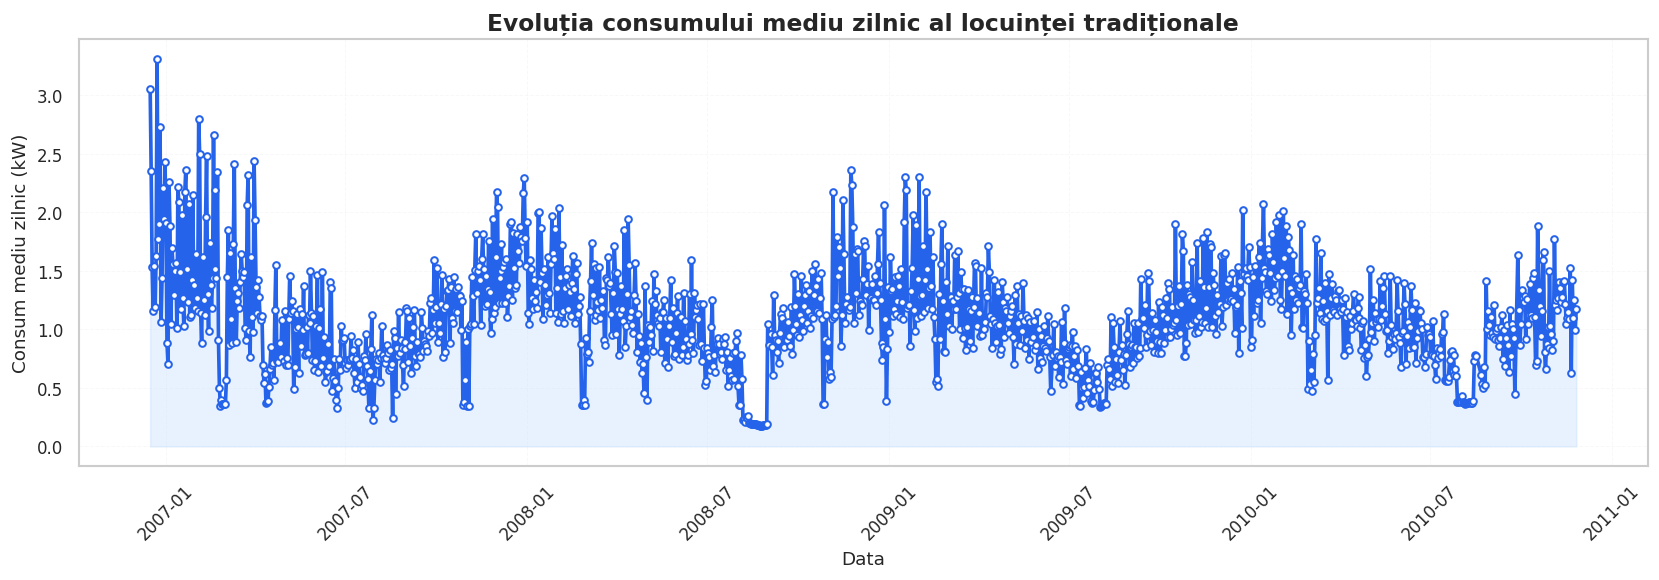

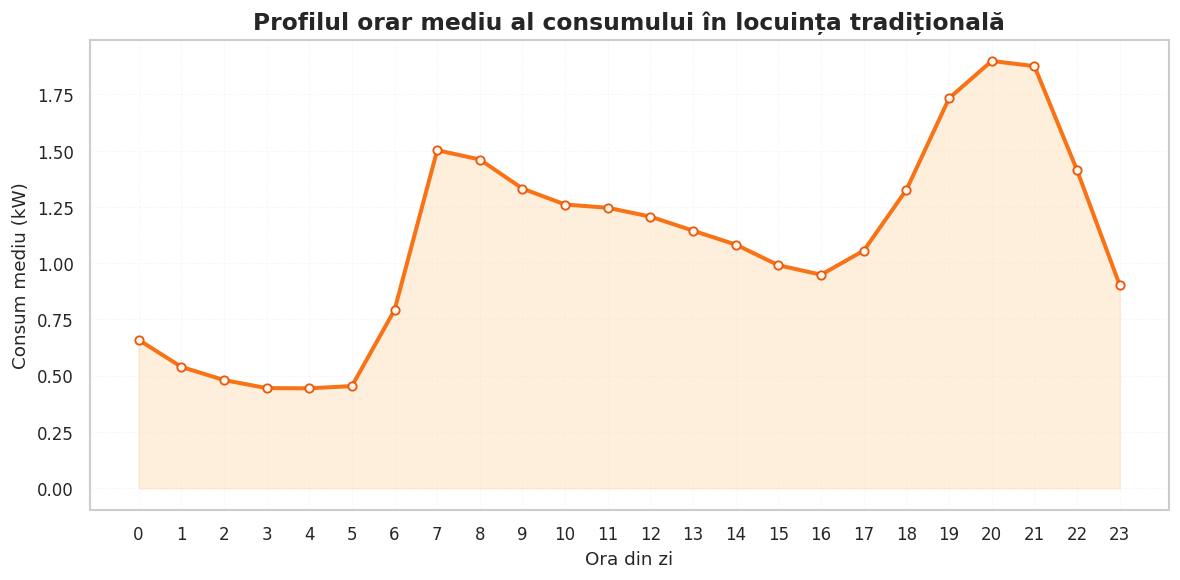

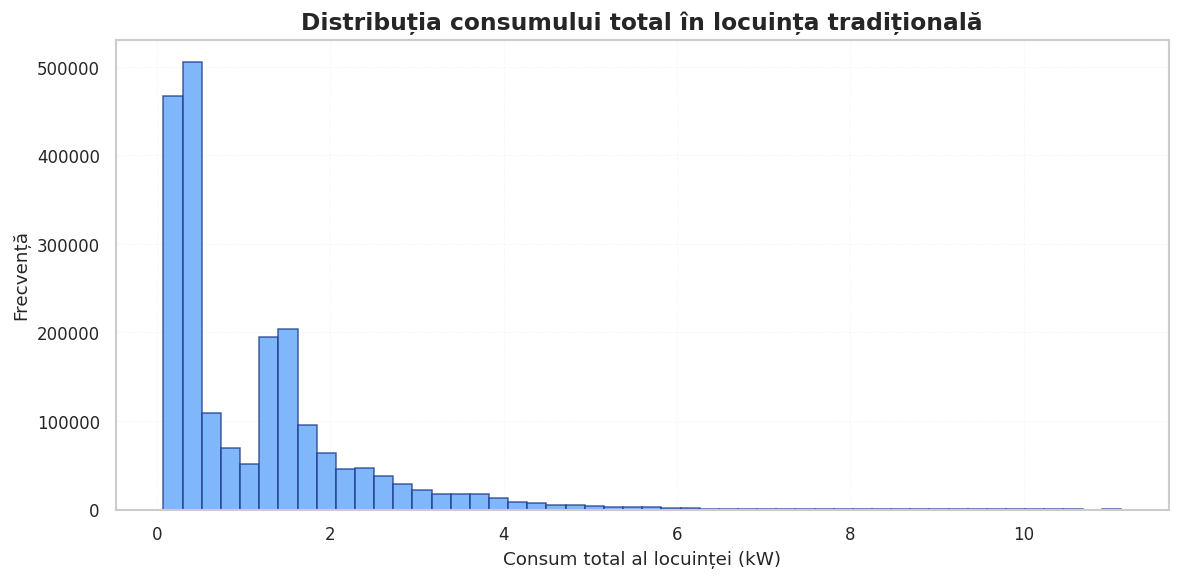

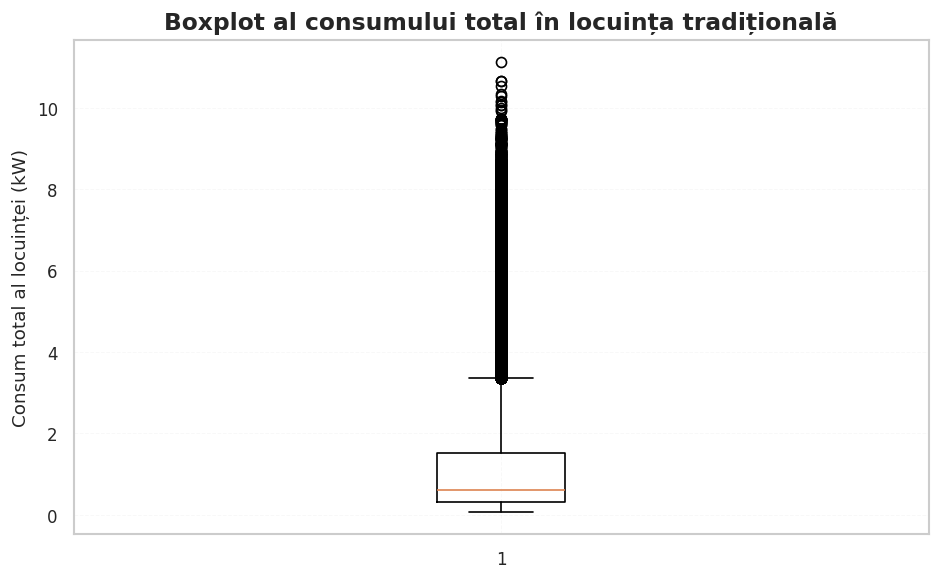

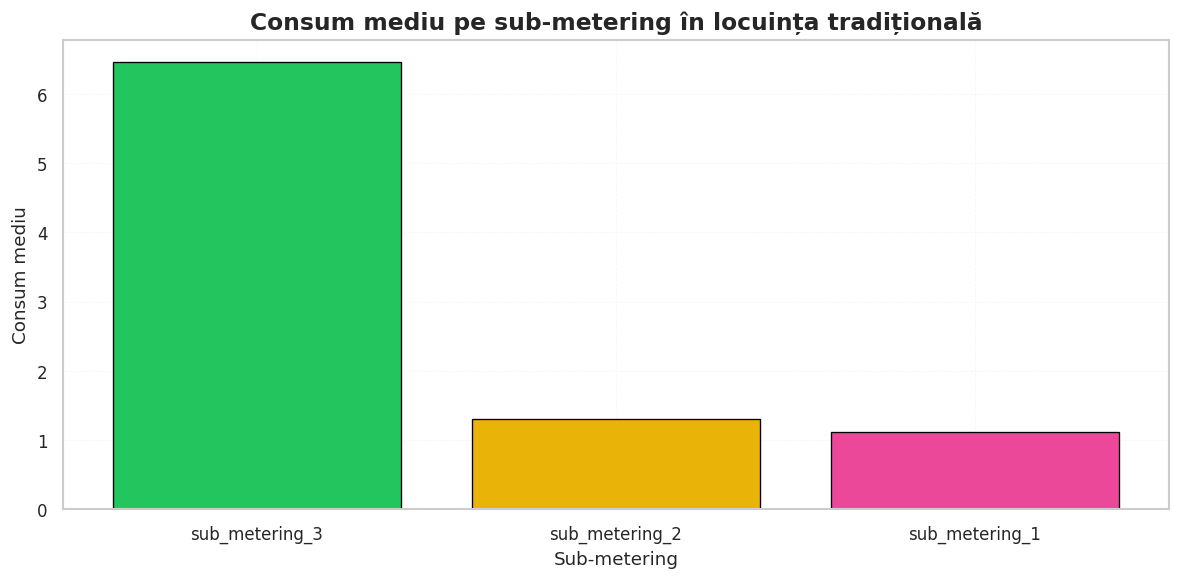

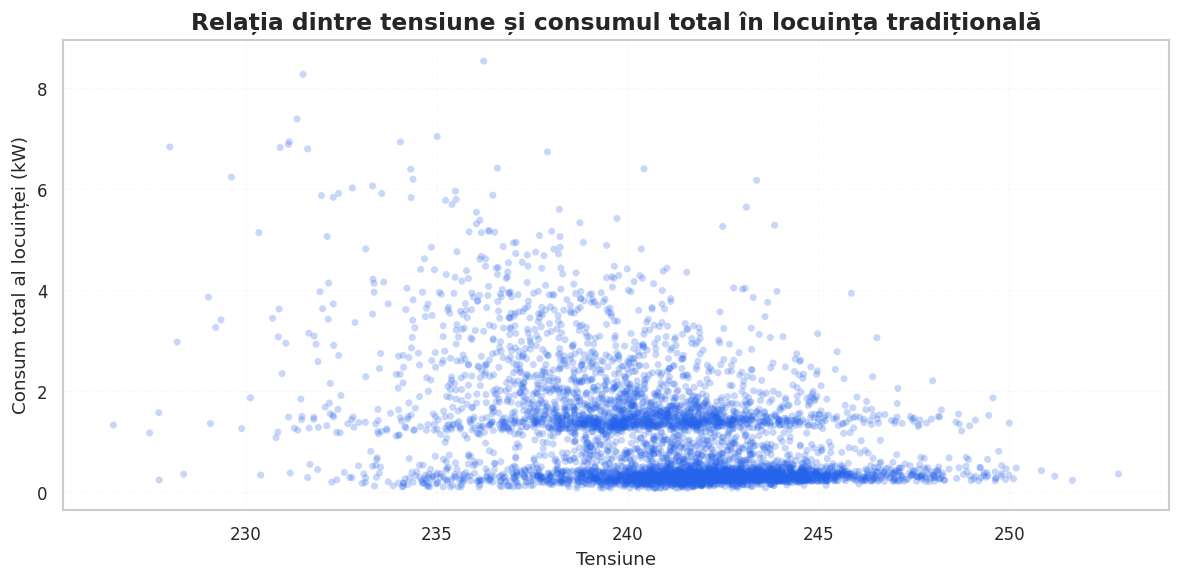

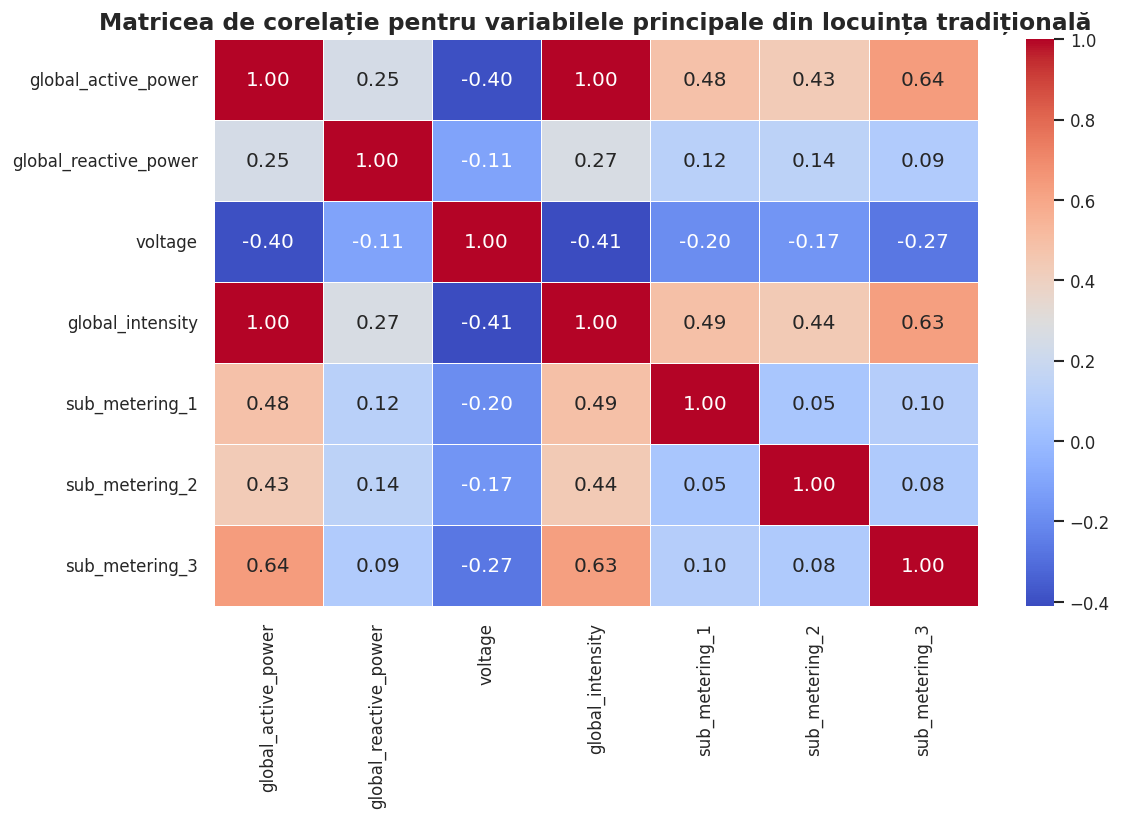

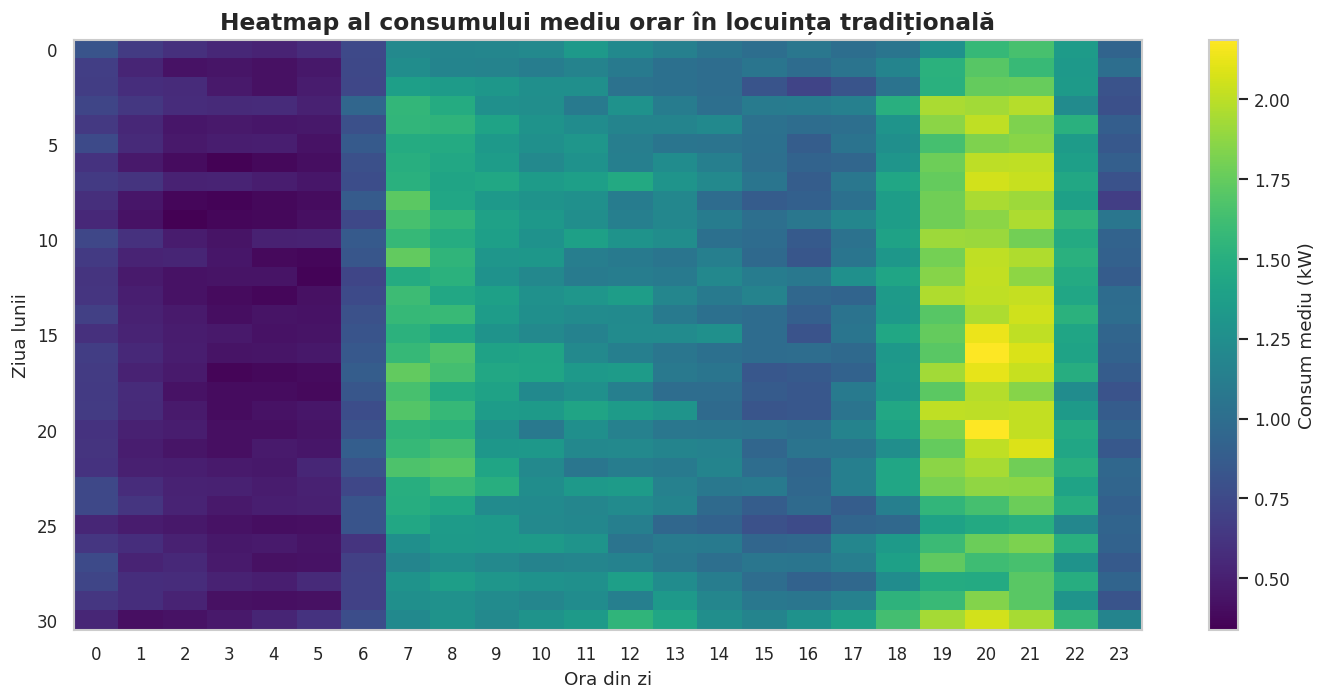

In [ ]:
# =========================================================
# TRADITIONAL HOME — PRELUCRAREA, ANALIZA ȘI VIZUALIZAREA DATELOR
# =========================================================

# =========================
# 1. Instalarea bibliotecilor și importul pachetelor
# =========================
!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, to_timestamp, year, month, dayofmonth, hour, dayofweek,
    avg, max as spark_max, min as spark_min, count, isnan, when,
    trim, regexp_replace, concat_ws, date_format
)
from pyspark.sql.types import DoubleType
from google.colab import files

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Stil general pentru grafice
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.linewidth"] = 0.6
plt.rcParams["grid.alpha"] = 0.12

# Paletă de culori
main_blue = "#2563eb"
soft_blue = "#bfdbfe"

# =========================
# 2. Inițializarea mediului Spark
# =========================
spark = SparkSession.builder \
    .appName("TraditionalHomePreprocessing") \
    .getOrCreate()

# =========================
# 3. Încărcarea setului de date
# =========================
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
print(f"Fișier selectat: {file_name}")

# =========================
# 4. Citirea și inspectarea inițială a setului de date
# =========================
df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True,
    sep=";",
    nullValue="?",
    mode="DROPMALFORMED"
)

print("Dimensiunea inițială a setului:")
print("Număr rânduri:", df.count())
print("Număr coloane:", len(df.columns))

print("\nSchema inițială a setului:")
df.printSchema()

print("\nPrimele rânduri:")
df.show(5, truncate=False)

# =========================
# 5. Redenumirea și standardizarea coloanelor
# =========================
rename_map = {
    "Global_active_power": "global_active_power",
    "Global_reactive_power": "global_reactive_power",
    "Voltage": "voltage",
    "Global_intensity": "global_intensity",
    "Sub_metering_1": "sub_metering_1",
    "Sub_metering_2": "sub_metering_2",
    "Sub_metering_3": "sub_metering_3"
}

for old_name, new_name in rename_map.items():
    if old_name in df.columns:
        df = df.withColumnRenamed(old_name, new_name)

print("Coloane după redenumire:")
print(df.columns)

# =========================
# 6. Curățarea și conversia variabilei temporale
# =========================
df = df.withColumn("Date", trim(col("Date")))
df = df.withColumn("Time", trim(col("Time").cast("string")))

# Dacă Spark a inferat Time greșit, extragem doar partea HH:mm:ss
df = df.withColumn("time_only", date_format(col("Time").cast("timestamp"), "HH:mm:ss"))
df = df.withColumn(
    "time_only",
    when(col("time_only").isNull(), col("Time")).otherwise(col("time_only"))
)

df = df.withColumn("timestamp_str", concat_ws(" ", col("Date"), col("time_only")))
df = df.withColumn("timestamp", to_timestamp(col("timestamp_str"), "d/M/yyyy HH:mm:ss"))
df = df.filter(col("timestamp").isNotNull())

print("\nDupă construirea coloanei timestamp:")
print("Număr rânduri:", df.count())
df.select("Date", "Time", "time_only", "timestamp").show(5, truncate=False)

# =========================
# 7. Curățarea generală a datelor
# =========================
numeric_cols = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_numeric_cols = [c for c in numeric_cols if c in df.columns]

for c in existing_numeric_cols:
    df = df.withColumn(c, regexp_replace(col(c).cast("string"), ",", "."))
    df = df.withColumn(c, col(c).cast(DoubleType()))

before = df.count()
df = df.dropDuplicates()
after = df.count()

print(f"\nRânduri înainte de eliminarea duplicatelor: {before}")
print(f"Rânduri după eliminarea duplicatelor: {after}")

essential_cols = [c for c in ["global_active_power"] if c in df.columns]
if essential_cols:
    df = df.dropna(subset=essential_cols)

print("\nNumăr rânduri după eliminarea valorilor esențiale lipsă:", df.count())

# =========================
# 8. Verificarea calității datelor
# =========================
missing_expr = [
    count(when(col(c).isNull() | isnan(col(c)), c)).alias(c)
    for c in existing_numeric_cols
]

missing_df = df.select(missing_expr)

print("\nValori lipsă pe coloane numerice:")
missing_df.show(truncate=False)

# =========================
# 9. Construirea variabilelor temporale și ordonarea cronologică
# =========================
df = df.withColumn("year", year(col("timestamp"))) \
       .withColumn("month", month(col("timestamp"))) \
       .withColumn("day", dayofmonth(col("timestamp"))) \
       .withColumn("hour", hour(col("timestamp"))) \
       .withColumn("day_of_week", dayofweek(col("timestamp")))

df = df.orderBy("timestamp")

print("\nPrimele rânduri din setul curățat și ordonat:")
df.show(5, truncate=False)

# =========================
# 10. Agregarea setului pe oră și pe zi
# =========================
hourly_df = df.groupBy("year", "month", "day", "hour").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day", "hour")

daily_df = df.groupBy("year", "month", "day").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day")

print("\nPrimele rânduri agregate pe oră:")
hourly_df.show(5, truncate=False)

print("\nPrimele rânduri agregate pe zi:")
daily_df.show(5, truncate=False)

# =========================
# 11. Salvarea seturilor prelucrate
# =========================
df_pd = df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()

df_pd.to_csv("traditional_home_cleaned.csv", index=False)
hourly_pd.to_csv("traditional_home_hourly.csv", index=False)
daily_pd.to_csv("traditional_home_daily.csv", index=False)

print("\nFișiere salvate cu succes:")
print("- traditional_home_cleaned.csv")
print("- traditional_home_hourly.csv")
print("- traditional_home_daily.csv")

# =========================
# 12. Selectarea variabilelor principale pentru analiză
# =========================
main_vars = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_main_vars = [c for c in main_vars if c in df.columns]

print("Variabile selectate pentru analiza ulterioară:")
print(existing_main_vars)

# =========================
# 13. Verificarea valorilor negative
# =========================
from pyspark.sql.functions import sum as spark_sum

negative_expr = [
    spark_sum(when(col(c) < 0, 1).otherwise(0)).alias(c)
    for c in existing_main_vars
]

negative_df = df.select(negative_expr)

print("\nNumăr de valori negative pe coloane:")
negative_df.show(truncate=False)

# =========================
# 14. Statistici descriptive preliminare
# =========================
print("\nStatistici descriptive preliminare:")
df.select(existing_main_vars).describe().show(truncate=False)

# =========================
# 15. Identificarea valorilor extreme prin metoda IQR
# =========================
for c in existing_main_vars:
    q1, q3 = df.approxQuantile(c, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers_count = df.filter((col(c) < lower_bound) | (col(c) > upper_bound)).count()

    print(f"\nVariabila: {c}")
    print(f"Q1 = {q1:.6f}")
    print(f"Q3 = {q3:.6f}")
    print(f"IQR = {iqr:.6f}")
    print(f"Limita inferioară = {lower_bound:.6f}")
    print(f"Limita superioară = {upper_bound:.6f}")
    print(f"Număr estimat de outlieri = {outliers_count}")

# =========================
# 16. Verificarea valorilor nule în variabilele selectate
# =========================
null_expr = [
    count(when(col(c).isNull(), c)).alias(c)
    for c in existing_main_vars
]

null_df = df.select(null_expr)

print("\nValori nule pe variabilele selectate:")
null_df.show(truncate=False)

# =========================
# 17. Construirea setului final pentru analiză
# =========================
analysis_df = df.select(["timestamp"] + existing_main_vars).orderBy("timestamp")

print("\nSetul final selectat pentru analiză:")
analysis_df.show(5, truncate=False)

print("Număr de coloane în setul final:", len(analysis_df.columns))
print("Coloanele setului final:")
print(analysis_df.columns)

# =========================
# 18. Conversia în Pandas pentru analiză și vizualizare
# =========================
analysis_pd = analysis_df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()

print("\nDimensiunea analysis_pd:", analysis_pd.shape)
print("Dimensiunea hourly_pd:", hourly_pd.shape)
print("Dimensiunea daily_pd:", daily_pd.shape)

# =========================
# 19. Statistici descriptive finale în Pandas
# =========================
desc_stats = analysis_pd[existing_main_vars].describe().T
desc_stats["median"] = analysis_pd[existing_main_vars].median()

print("Statistici descriptive pentru setul tradițional:")
display(desc_stats)

# =========================
# 20. Construirea variabilelor temporale pentru vizualizare
# =========================
hourly_pd["datetime"] = pd.to_datetime(hourly_pd[["year", "month", "day", "hour"]])
daily_pd["date"] = pd.to_datetime(daily_pd[["year", "month", "day"]])

analysis_pd["timestamp"] = pd.to_datetime(analysis_pd["timestamp"], errors="coerce")
analysis_pd["date_only"] = analysis_pd["timestamp"].dt.date
analysis_pd["hour"] = analysis_pd["timestamp"].dt.hour

# =========================
# 21. Calculul energiei consumate și selecția zilelor utilizabile
# =========================
traditional_energy_pd = analysis_pd[["timestamp", "global_active_power"]].copy()
traditional_energy_pd = traditional_energy_pd.dropna(subset=["timestamp", "global_active_power"]).copy()
traditional_energy_pd = traditional_energy_pd.sort_values("timestamp").reset_index(drop=True)

traditional_energy_pd["date_only"] = traditional_energy_pd["timestamp"].dt.date
traditional_energy_pd["hour"] = traditional_energy_pd["timestamp"].dt.hour

# Date pe minut => energie/minut
traditional_energy_pd["energy_kwh"] = traditional_energy_pd["global_active_power"] / 60.0

daily_counts_pd = traditional_energy_pd.groupby("date_only").size().reset_index(name="rows_per_day")

daily_energy_pd = traditional_energy_pd.groupby("date_only", as_index=False)["energy_kwh"].sum()
daily_energy_pd = daily_energy_pd.rename(columns={"energy_kwh": "daily_energy_kwh"})
daily_energy_pd = daily_energy_pd.merge(daily_counts_pd, on="date_only", how="left")

# zile aproape complete
usable_daily_pd = daily_energy_pd[daily_energy_pd["rows_per_day"] >= 1440 * 0.95].copy()

print("Consum zilnic observat:")
display(daily_energy_pd.head())

print("Zile utilizabile:")
display(usable_daily_pd.head())

usable_days = set(usable_daily_pd["date_only"])
traditional_usable_pd = traditional_energy_pd[traditional_energy_pd["date_only"].isin(usable_days)].copy()

print("Număr zile utilizabile:", len(usable_daily_pd))
print("Număr rânduri utilizate:", len(traditional_usable_pd))

# =========================
# 22. Calculul indicatorilor energetici principali
# =========================
avg_daily_kwh = usable_daily_pd["daily_energy_kwh"].mean()

# Pentru consistență metodologică cu smart:
estimated_monthly_kwh = avg_daily_kwh * 30.4
annual_estimated_kwh = avg_daily_kwh * 365

min_daily_kwh = usable_daily_pd["daily_energy_kwh"].min()
max_daily_kwh = usable_daily_pd["daily_energy_kwh"].max()

# și indicatorul lunar observat, separat
traditional_usable_pd["year_month"] = traditional_usable_pd["timestamp"].dt.to_period("M").astype(str)
monthly_energy_real = traditional_usable_pd.groupby("year_month", as_index=False)["energy_kwh"].sum()
monthly_energy_real = monthly_energy_real.rename(columns={"energy_kwh": "monthly_energy_kwh"})

avg_monthly_observed_kwh = monthly_energy_real["monthly_energy_kwh"].mean()

max_month_row = monthly_energy_real.loc[monthly_energy_real["monthly_energy_kwh"].idxmax()]
max_monthly_observed_kwh = max_month_row["monthly_energy_kwh"]
max_monthly_observed_label = max_month_row["year_month"]

mean_observed_power = traditional_usable_pd["global_active_power"].mean()

print("=== INDICATORI ENERGETICI PRINCIPALI ===")
print(f"Consum mediu zilnic: {avg_daily_kwh:.2f} kWh/zi")
print(f"Consum lunar estimat (logică unificată): {estimated_monthly_kwh:.2f} kWh/lună")
print(f"Consum anual estimat: {annual_estimated_kwh:.2f} kWh/an")
print(f"Consum mediu lunar observat: {avg_monthly_observed_kwh:.2f} kWh/lună")
print(f"Consum minim zilnic: {min_daily_kwh:.2f} kWh/zi")
print(f"Consum maxim zilnic: {max_daily_kwh:.2f} kWh/zi")
print(f"Consum maxim lunar observat: {max_monthly_observed_kwh:.2f} kWh/lună")
print(f"Luna consumului maxim lunar observat: {max_monthly_observed_label}")
print(f"Putere medie observată: {mean_observed_power:.4f} kW")

# =========================
# 23. Calculul profilului orar și al orelor de vârf
# =========================
hourly_daily_pd = traditional_usable_pd.groupby(["date_only", "hour"], as_index=False)["energy_kwh"].sum()
hourly_daily_pd = hourly_daily_pd.rename(columns={"energy_kwh": "hourly_energy_kwh"})

hourly_profile_pd = hourly_daily_pd.groupby("hour", as_index=False)["hourly_energy_kwh"].mean()
hourly_profile_pd = hourly_profile_pd.rename(columns={"hourly_energy_kwh": "avg_hourly_kwh"})

print("\nProfil orar mediu:")
display(hourly_profile_pd)

peak_hour_row = hourly_profile_pd.loc[hourly_profile_pd["avg_hourly_kwh"].idxmax()]
peak_hour = int(peak_hour_row["hour"])
peak_hour_avg_kwh = peak_hour_row["avg_hourly_kwh"]

peak_hour_all_days = hourly_daily_pd[hourly_daily_pd["hour"] == peak_hour].copy()
peak_hour_max_kwh = peak_hour_all_days["hourly_energy_kwh"].max()

all_hours = pd.DataFrame({"hour": range(24)})
hourly_profile_full = all_hours.merge(hourly_profile_pd, on="hour", how="left")
hourly_profile_full["avg_hourly_kwh"] = hourly_profile_full["avg_hourly_kwh"].fillna(0)

windows = []
for start in range(0, 24, 3):
    mask = (hourly_profile_full["hour"] >= start) & (hourly_profile_full["hour"] < start + 3)
    window_sum = hourly_profile_full.loc[mask, "avg_hourly_kwh"].sum()
    label = f"{start:02d}:00-{(start+3)%24:02d}:00"
    windows.append({"interval": label, "window_kwh": window_sum})

windows_df = pd.DataFrame(windows)
peak_window_row = windows_df.loc[windows_df["window_kwh"].idxmax()]
peak_window = peak_window_row["interval"]
peak_window_kwh = peak_window_row["window_kwh"]

print("\nFerestre de 3 ore:")
display(windows_df.sort_values("window_kwh", ascending=False))

print(f"Ora de vârf: {peak_hour:02d}:00")
print(f"Consum mediu la ora de vârf: {peak_hour_avg_kwh:.2f} kWh")
print(f"Consum maxim la ora de vârf: {peak_hour_max_kwh:.2f} kWh")
print(f"Interval de vârf: {peak_window}")
print(f"Consum cumulat în intervalul de vârf: {peak_window_kwh:.2f} kWh")

# =========================
# 24. Construirea tabelului final cu indicatorii energetici ai locuinței tradiționale
# =========================
summary_traditional = pd.DataFrame({
    "Indicator": [
        "Consum mediu zilnic",
        "Consum lunar estimat",
        "Consum anual estimat",
        "Consum mediu lunar observat",
        "Consum minim zilnic",
        "Consum maxim zilnic",
        "Consum maxim lunar observat",
        "Luna consumului maxim lunar observat",
        "Putere medie observată",
        "Ora de vârf",
        "Consum mediu la ora de vârf",
        "Consum maxim la ora de vârf",
        "Interval de vârf (3h)",
        "Consum cumulat în intervalul de vârf"
    ],
    "Valoare": [
        f"{avg_daily_kwh:.2f} kWh/zi",
        f"{estimated_monthly_kwh:.2f} kWh/lună",
        f"{annual_estimated_kwh:.2f} kWh/an",
        f"{avg_monthly_observed_kwh:.2f} kWh/lună",
        f"{min_daily_kwh:.2f} kWh/zi",
        f"{max_daily_kwh:.2f} kWh/zi",
        f"{max_monthly_observed_kwh:.2f} kWh/lună",
        f"{max_monthly_observed_label}",
        f"{mean_observed_power:.4f} kW",
        f"{peak_hour:02d}:00",
        f"{peak_hour_avg_kwh:.2f} kWh",
        f"{peak_hour_max_kwh:.2f} kWh",
        peak_window,
        f"{peak_window_kwh:.2f} kWh"
    ]
})

print("\n=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===")
display(summary_traditional)

# =========================
# 25. Graficul evoluției consumului mediu zilnic
# =========================
plt.figure(figsize=(14, 5))
plt.plot(
    daily_pd["date"],
    daily_pd["avg_global_active_power"],
    color=main_blue,
    linewidth=2.2,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgewidth=1.2
)
plt.fill_between(
    daily_pd["date"],
    daily_pd["avg_global_active_power"],
    color=soft_blue,
    alpha=0.35
)
plt.xlabel("Data")
plt.ylabel("Consum mediu zilnic (kW)")
plt.title("Evoluția consumului mediu zilnic al locuinței tradiționale")
plt.xticks(rotation=45)
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 26. Graficul profilului orar mediu
# =========================
hour_profile = hourly_pd.groupby("hour")["avg_global_active_power"].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(
    hour_profile["hour"],
    hour_profile["avg_global_active_power"],
    color="#f97316",
    linewidth=2.4,
    marker="o",
    markersize=5,
    markerfacecolor="#fff7ed",
    markeredgecolor="#ea580c",
    markeredgewidth=1.1
)
plt.fill_between(
    hour_profile["hour"],
    hour_profile["avg_global_active_power"],
    color="#fed7aa",
    alpha=0.4
)
plt.xlabel("Ora din zi")
plt.ylabel("Consum mediu (kW)")
plt.title("Profilul orar mediu al consumului în locuința tradițională")
plt.xticks(range(0, 24))
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 27. Histograma distribuției consumului total
# =========================
plt.figure(figsize=(10, 5))
plt.hist(
    analysis_pd["global_active_power"].dropna(),
    bins=50,
    color="#60a5fa",
    edgecolor="#1e3a8a",
    linewidth=0.9,
    alpha=0.8
)
plt.xlabel("Consum total al locuinței (kW)")
plt.ylabel("Frecvență")
plt.title("Distribuția consumului total în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 28. Boxplot-ul consumului total
# =========================
plt.figure(figsize=(8, 5))
plt.boxplot(analysis_pd["global_active_power"].dropna(), vert=True)
plt.ylabel("Consum total al locuinței (kW)")
plt.title("Boxplot al consumului total în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 29. Graficul consumului mediu pe sub-metering
# =========================
sub_cols = ["sub_metering_1", "sub_metering_2", "sub_metering_3"]
existing_sub_cols = [c for c in sub_cols if c in analysis_pd.columns]

sub_means = analysis_pd[existing_sub_cols].mean().sort_values(ascending=False)
bar_colors = ["#22c55e", "#eab308", "#ec4899"][:len(sub_means)]

plt.figure(figsize=(10, 5))
plt.bar(
    sub_means.index,
    sub_means.values,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8
)
plt.xlabel("Sub-metering")
plt.ylabel("Consum mediu")
plt.title("Consum mediu pe sub-metering în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 30. Relația dintre tensiune și consumul total
# =========================
if "voltage" in analysis_pd.columns and "global_active_power" in analysis_pd.columns:
    volt_cons_df = analysis_pd[["voltage", "global_active_power"]].dropna()
    sample_pd = volt_cons_df.sample(
        min(5000, len(volt_cons_df)),
        random_state=42
    )

    plt.figure(figsize=(10, 5))
    plt.scatter(
        sample_pd["voltage"],
        sample_pd["global_active_power"],
        color=main_blue,
        alpha=0.25,
        edgecolors="none",
        s=18
    )
    plt.xlabel("Tensiune")
    plt.ylabel("Consum total al locuinței (kW)")
    plt.title("Relația dintre tensiune și consumul total în locuința tradițională")
    ax = plt.gca()
    ax.set_facecolor("white")
    ax.grid(True, axis="y")
    plt.tight_layout()
    plt.show()

# =========================
# 31. Heatmap-ul corelațiilor dintre variabilele principale
# =========================
corr_vars = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_corr_vars = [c for c in corr_vars if c in analysis_pd.columns]
corr_matrix = analysis_pd[existing_corr_vars].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matricea de corelație pentru variabilele principale din locuința tradițională")
plt.tight_layout()
plt.show()

# =========================
# 32. Heatmap-ul consumului mediu orar pe zile
# =========================
if {"day", "hour", "avg_global_active_power"}.issubset(hourly_pd.columns):
    heatmap_data = hourly_pd.pivot_table(
        index="day",
        columns="hour",
        values="avg_global_active_power",
        aggfunc="mean"
    )

    plt.figure(figsize=(12, 6))
    plt.imshow(heatmap_data, aspect="auto", cmap="viridis")
    plt.colorbar(label="Consum mediu (kW)")
    plt.xlabel("Ora din zi")
    plt.ylabel("Ziua lunii")
    plt.title("Heatmap al consumului mediu orar în locuința tradițională")
    plt.xticks(range(24))
    ax = plt.gca()
    ax.grid(False)
    ax.set_facecolor("white")
    plt.tight_layout()
    plt.show()

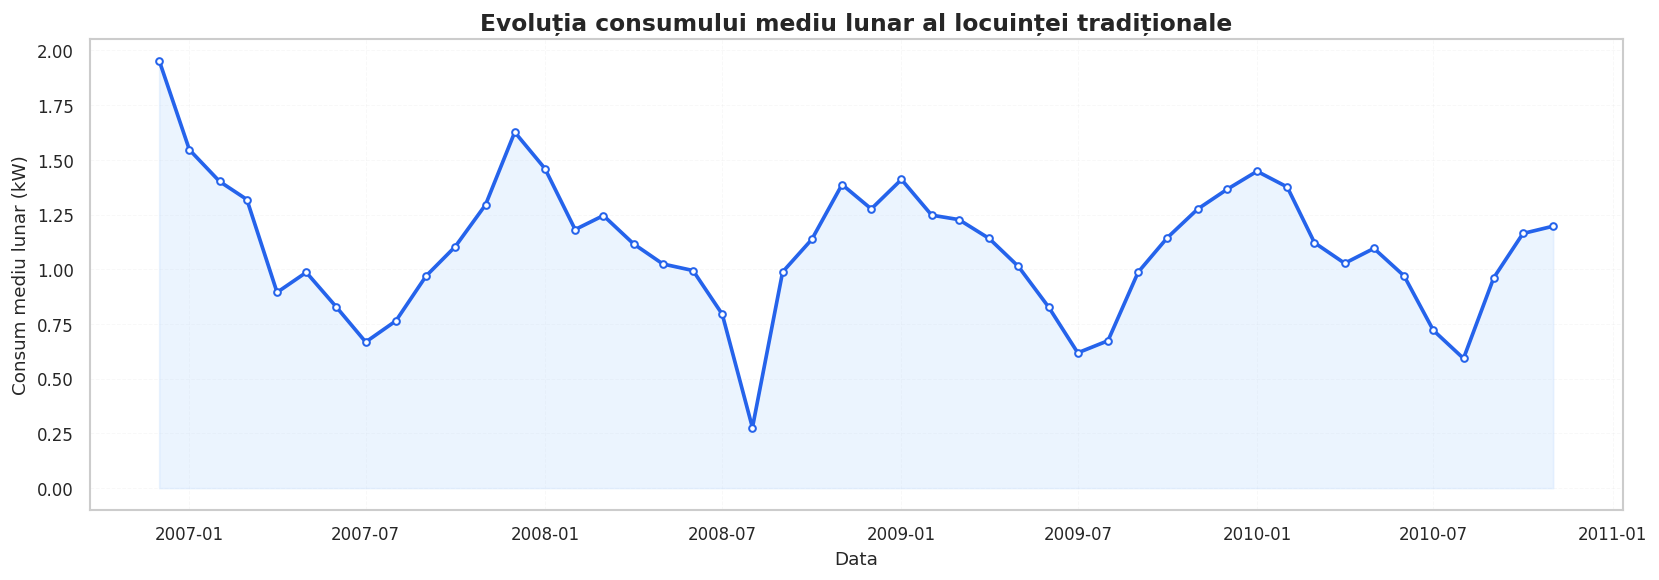

In [ ]:
daily_pd["date"] = pd.to_datetime(daily_pd["date"])
daily_pd["year_month"] = daily_pd["date"].dt.to_period("M").astype(str)

monthly_vis = daily_pd.groupby("year_month", as_index=False)["avg_global_active_power"].mean()
monthly_vis["year_month"] = pd.to_datetime(monthly_vis["year_month"])

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_vis["year_month"],
    monthly_vis["avg_global_active_power"],
    color=main_blue,
    linewidth=2.2,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgewidth=1.2
)
plt.fill_between(
    monthly_vis["year_month"],
    monthly_vis["avg_global_active_power"],
    color=soft_blue,
    alpha=0.3
)
plt.xlabel("Data")
plt.ylabel("Consum mediu lunar (kW)")
plt.title("Evoluția consumului mediu lunar al locuinței tradiționale")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

Saving household_power_consumption.csv to household_power_consumption.csv
Fișier selectat: household_power_consumption.csv
Dimensiunea inițială a setului:
Număr rânduri: 2075259
Număr coloane: 9

Schema inițială a setului:
root
 |-- Date: string (nullable = true)
 |-- Time: timestamp (nullable = true)
 |-- Global_active_power: double (nullable = true)
 |-- Global_reactive_power: double (nullable = true)
 |-- Voltage: double (nullable = true)
 |-- Global_intensity: double (nullable = true)
 |-- Sub_metering_1: double (nullable = true)
 |-- Sub_metering_2: double (nullable = true)
 |-- Sub_metering_3: double (nullable = true)


Primele rânduri:
+----------+-------------------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|Date      |Time               |Global_active_power|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+----------+-------------------+-------------------+-------

,count,mean,std,min,25%,50%,75%,max,median
global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122,0.602
global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390,0.100
voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150,241.010
global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400,2.600
sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000,0.000
sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000,0.000
sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000,1.000


Consum zilnic observat:


,date_only,daily_energy_kwh,rows_per_day
0,2006-12-16,20.152933,396
1,2006-12-17,56.507667,1440
2,2006-12-18,36.730433,1440
3,2006-12-19,27.769900,1440
4,2006-12-20,37.095800,1440


Zile utilizabile:


,date_only,daily_energy_kwh,rows_per_day
1,2006-12-17,56.507667,1440
2,2006-12-18,36.730433,1440
3,2006-12-19,27.769900,1440
4,2006-12-20,37.095800,1440
5,2006-12-21,28.610400,1438


... (2 outputs left out)


Ferestre de 3 ore:


,interval,window_kwh
6,18:00-21:00,4.958530
7,21:00-00:00,4.191216
3,09:00-12:00,3.837219
2,06:00-09:00,3.753471
4,12:00-15:00,3.434038
5,15:00-18:00,2.995542
0,00:00-03:00,1.680600
1,03:00-06:00,1.342938


Ora de vârf: 20:00
Consum mediu la ora de vârf: 1.90 kWh
Consum maxim la ora de vârf: 6.52 kWh
Interval de vârf: 18:00-21:00
Consum cumulat în intervalul de vârf: 4.96 kWh

=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===


,Categorie,Indicator,Valoare
0,Observat real,Consum mediu lunar observat,773.26 kWh/lună
1,Observat real,Consum maxim lunar observat,1210.07 kWh/lună
2,Observat real,Luna consumului maxim lunar observat,2007-12
3,Comparabil cu smart,Consum mediu zilnic,26.19 kWh/zi
4,Comparabil cu smart,Consum lunar estimat,796.28 kWh/lună
5,Comparabil cu smart,Consum anual estimat,9560.65 kWh/an
6,Comparabil cu smart,Consum minim zilnic,4.17 kWh/zi
7,Comparabil cu smart,Consum maxim zilnic,79.56 kWh/zi
8,Comparabil cu smart,Putere medie observată,1.0916 kW
9,Comparabil cu smart,Ora de vârf,20:00


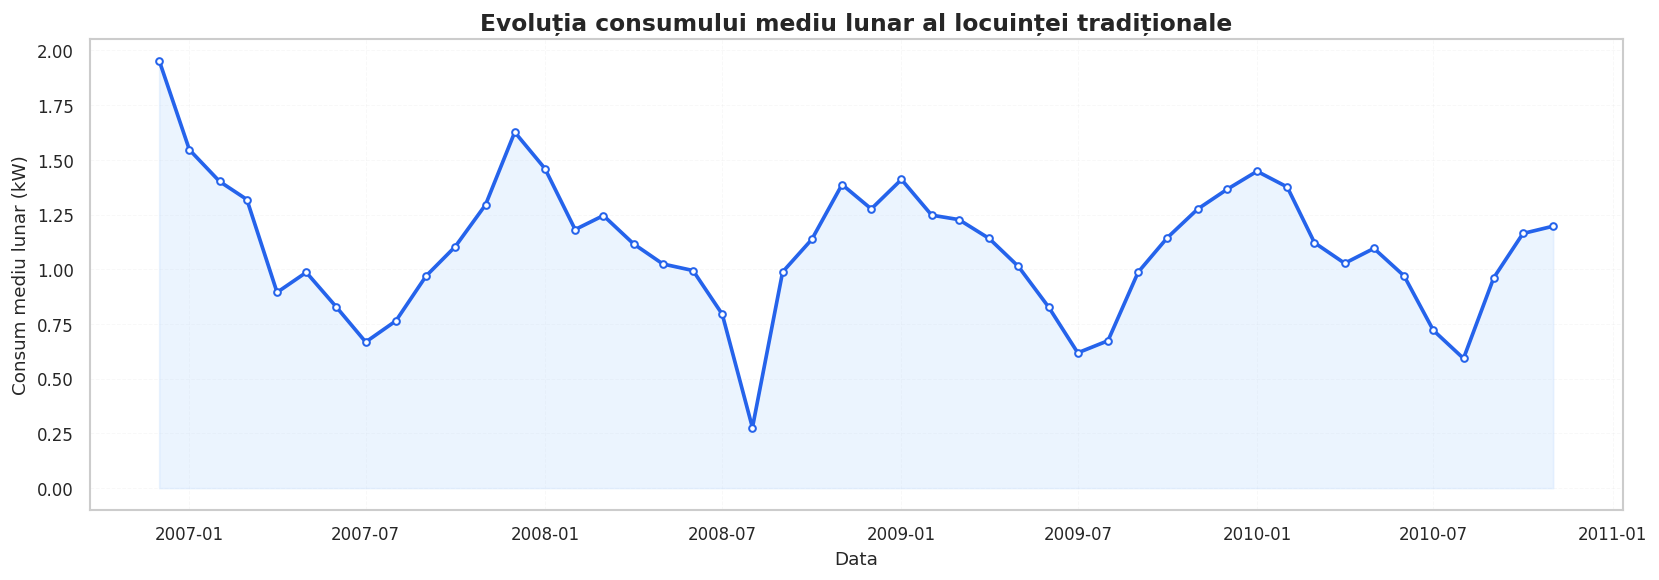

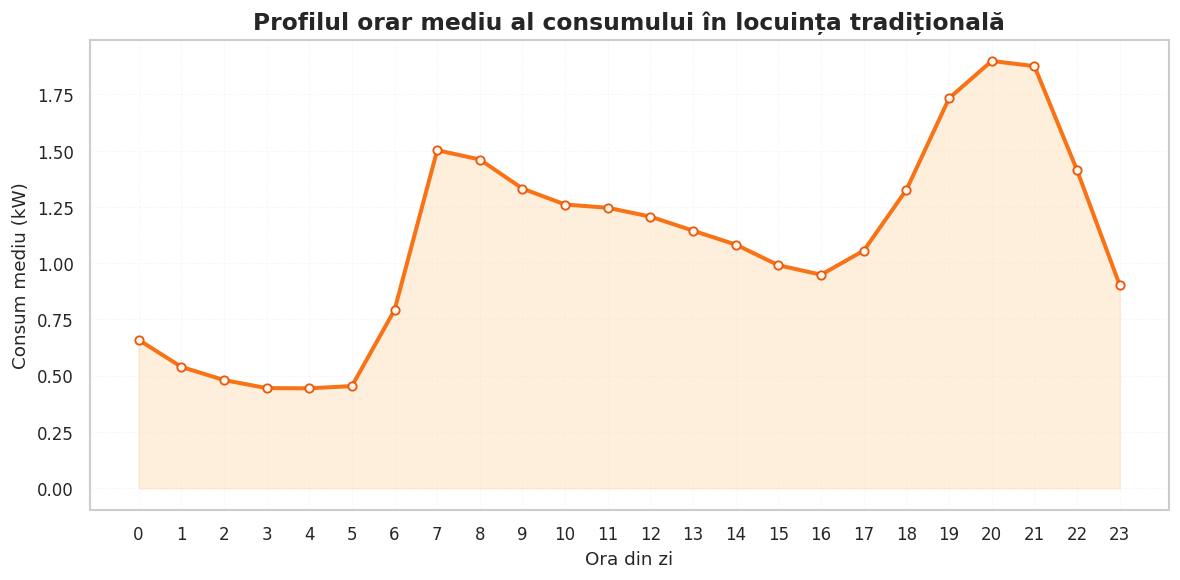

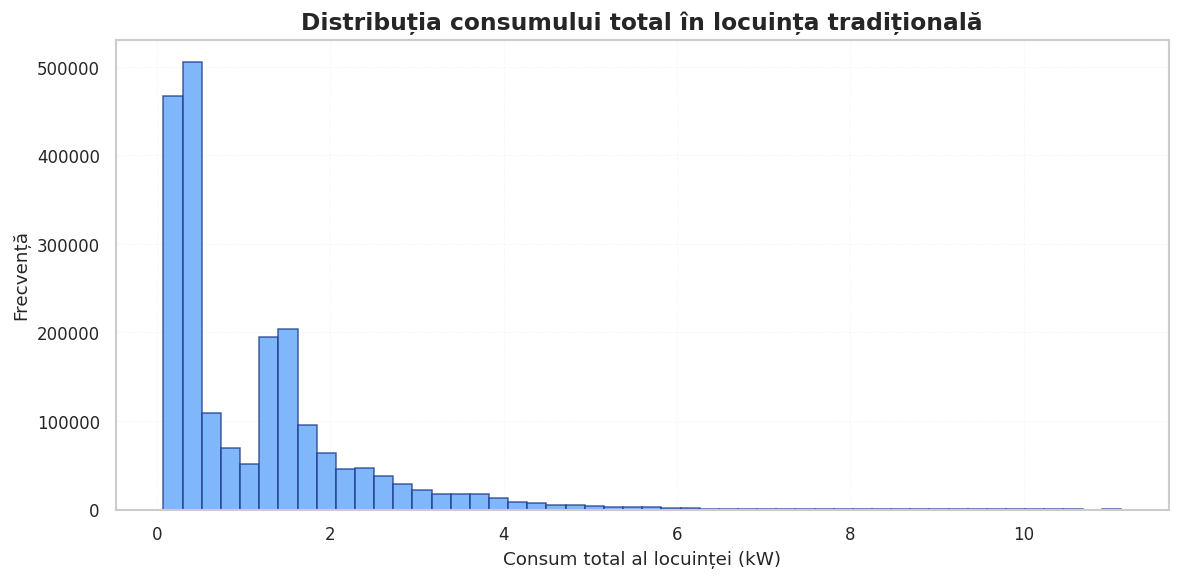

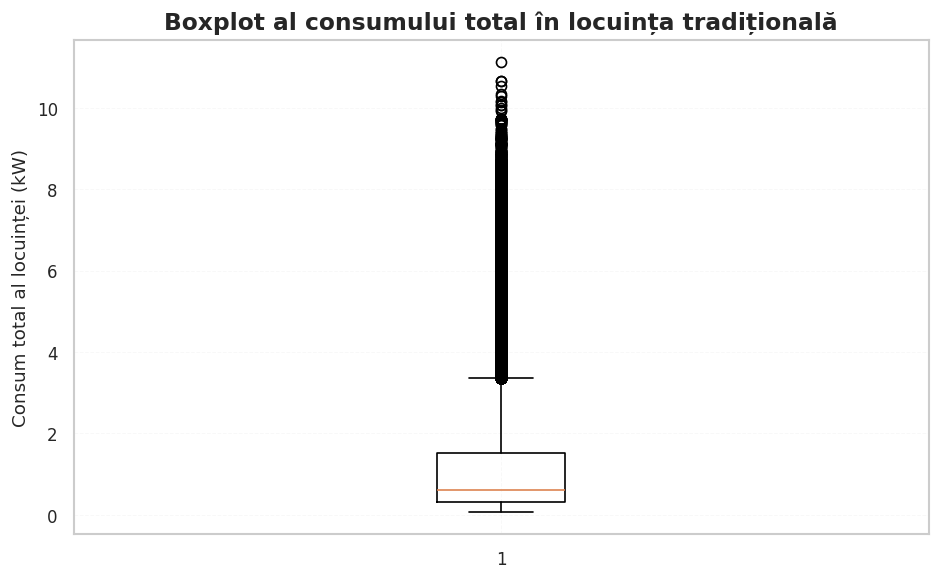

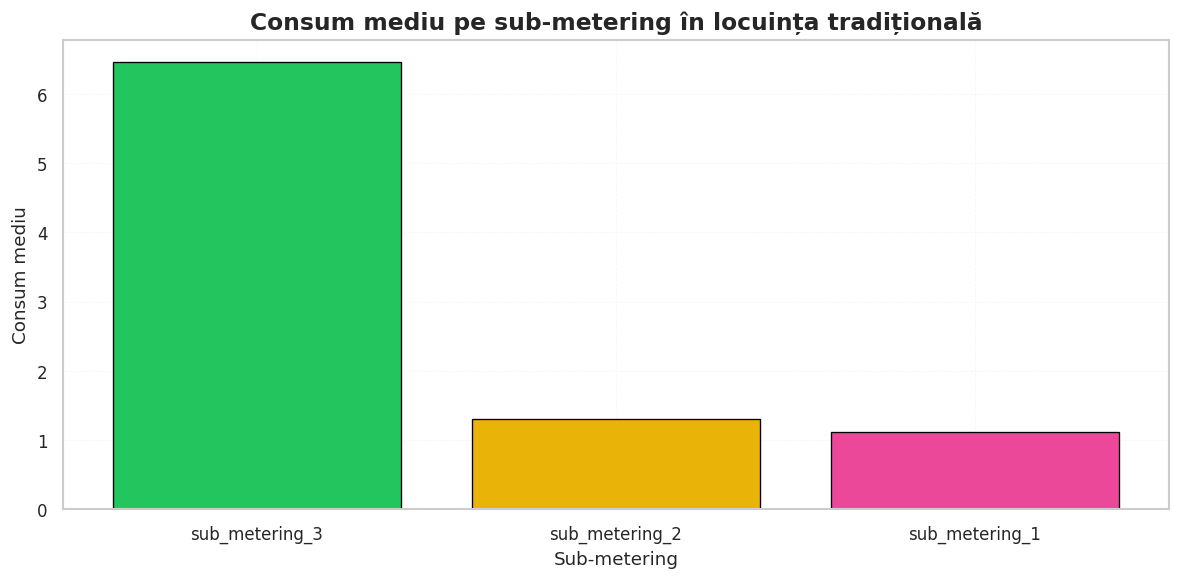

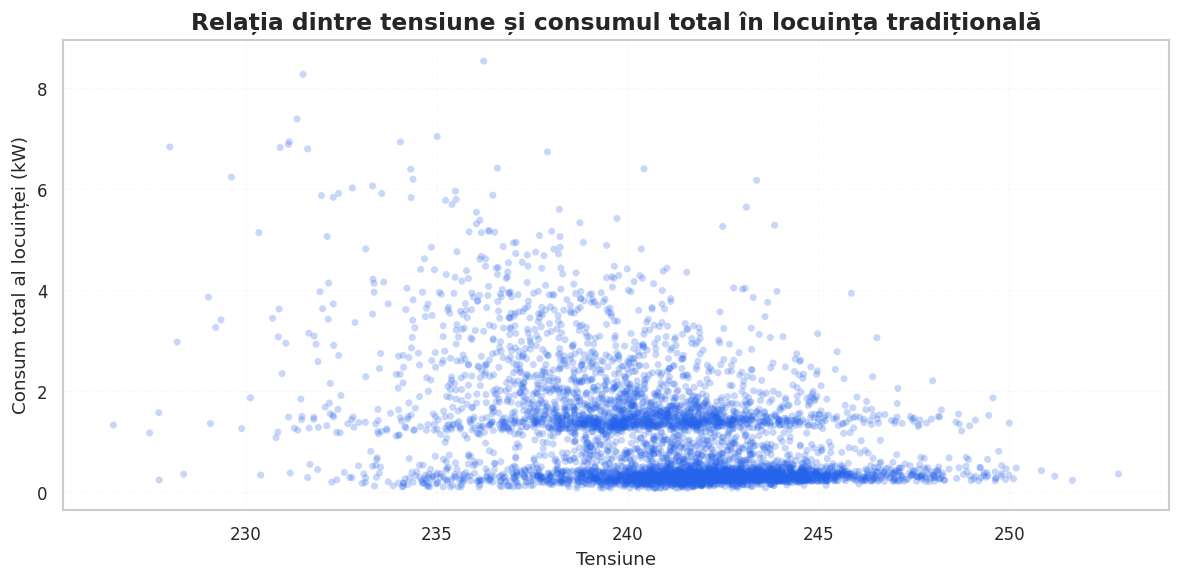

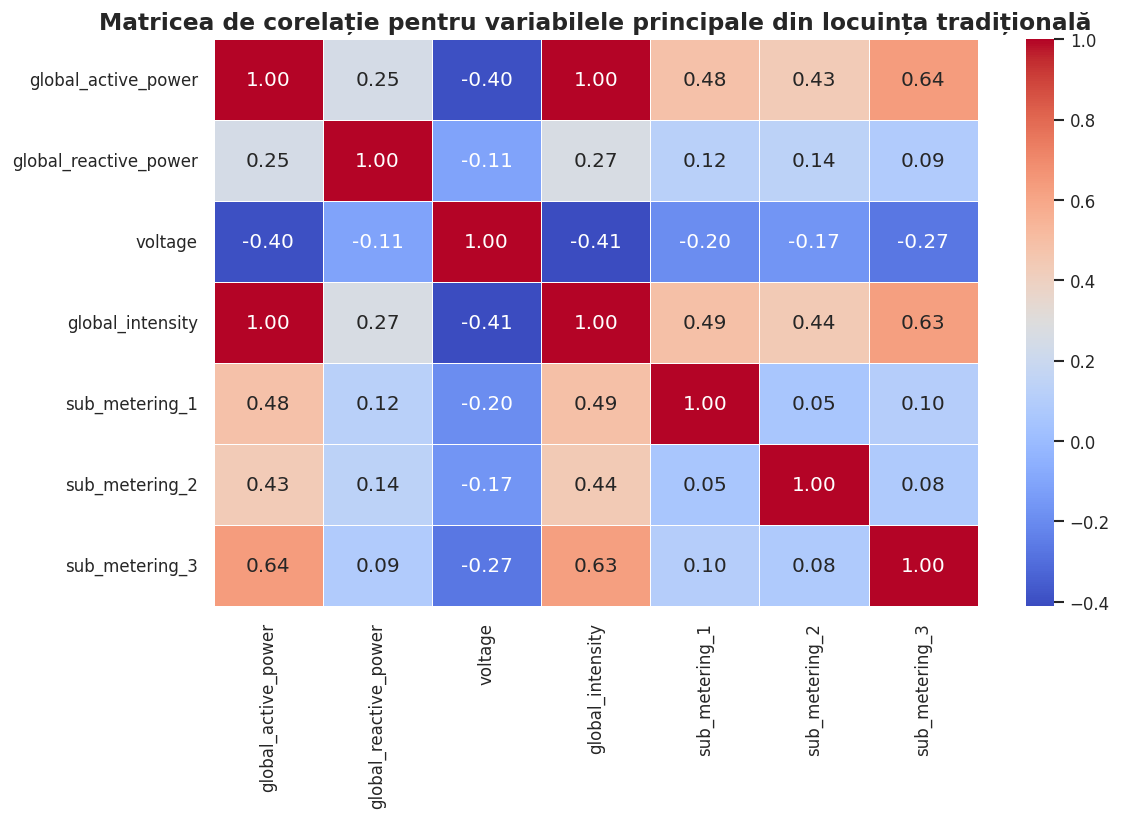

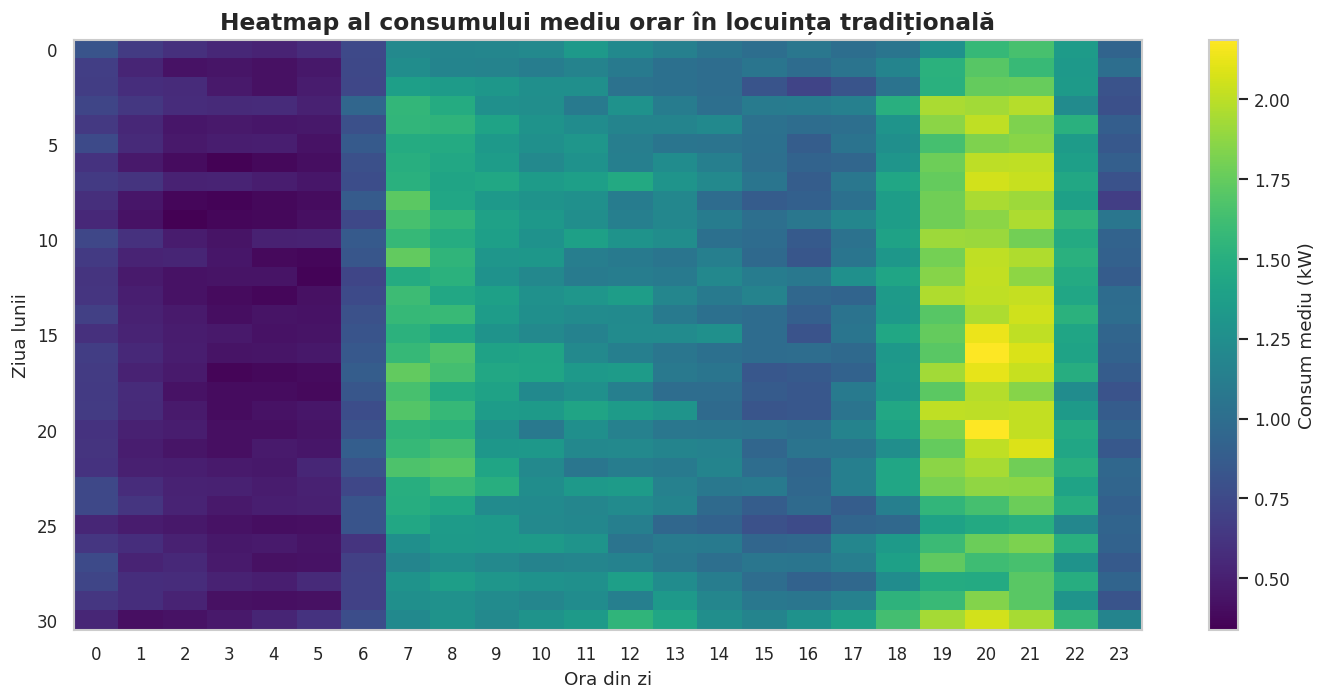

In [ ]:
# =========================================================
# TRADITIONAL HOME — PRELUCRAREA, ANALIZA ȘI VIZUALIZAREA DATELOR
# =========================================================

# =========================
# 1. Instalarea bibliotecilor și importul pachetelor
# =========================
!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, to_timestamp, year, month, dayofmonth, hour, dayofweek,
    avg, max as spark_max, min as spark_min, count, isnan, when,
    trim, regexp_replace, concat_ws, date_format
)
from pyspark.sql.types import DoubleType
from google.colab import files

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Stil general pentru grafice
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["grid.linewidth"] = 0.6
plt.rcParams["grid.alpha"] = 0.12

# Paletă de culori
main_blue = "#2563eb"
soft_blue = "#bfdbfe"

# =========================
# 2. Inițializarea mediului Spark
# =========================
spark = SparkSession.builder \
    .appName("TraditionalHomePreprocessing") \
    .getOrCreate()

# =========================
# 3. Încărcarea setului de date
# =========================
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
print(f"Fișier selectat: {file_name}")

# =========================
# 4. Citirea și inspectarea inițială a setului de date
# =========================
df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=True,
    sep=";",
    nullValue="?",
    mode="DROPMALFORMED"
)

print("Dimensiunea inițială a setului:")
print("Număr rânduri:", df.count())
print("Număr coloane:", len(df.columns))

print("\nSchema inițială a setului:")
df.printSchema()

print("\nPrimele rânduri:")
df.show(5, truncate=False)

# =========================
# 5. Redenumirea și standardizarea coloanelor
# =========================
rename_map = {
    "Global_active_power": "global_active_power",
    "Global_reactive_power": "global_reactive_power",
    "Voltage": "voltage",
    "Global_intensity": "global_intensity",
    "Sub_metering_1": "sub_metering_1",
    "Sub_metering_2": "sub_metering_2",
    "Sub_metering_3": "sub_metering_3"
}

for old_name, new_name in rename_map.items():
    if old_name in df.columns:
        df = df.withColumnRenamed(old_name, new_name)

print("Coloane după redenumire:")
print(df.columns)

# =========================
# 6. Curățarea și conversia variabilei temporale
# =========================
df = df.withColumn("Date", trim(col("Date")))
df = df.withColumn("Time", trim(col("Time").cast("string")))

df = df.withColumn("time_only", date_format(col("Time").cast("timestamp"), "HH:mm:ss"))
df = df.withColumn(
    "time_only",
    when(col("time_only").isNull(), col("Time")).otherwise(col("time_only"))
)

df = df.withColumn("timestamp_str", concat_ws(" ", col("Date"), col("time_only")))
df = df.withColumn("timestamp", to_timestamp(col("timestamp_str"), "d/M/yyyy HH:mm:ss"))
df = df.filter(col("timestamp").isNotNull())

print("\nDupă construirea coloanei timestamp:")
print("Număr rânduri:", df.count())
df.select("Date", "Time", "time_only", "timestamp").show(5, truncate=False)

# =========================
# 7. Curățarea generală a datelor
# =========================
numeric_cols = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_numeric_cols = [c for c in numeric_cols if c in df.columns]

for c in existing_numeric_cols:
    df = df.withColumn(c, regexp_replace(col(c).cast("string"), ",", "."))
    df = df.withColumn(c, col(c).cast(DoubleType()))

before = df.count()
df = df.dropDuplicates()
after = df.count()

print(f"\nRânduri înainte de eliminarea duplicatelor: {before}")
print(f"Rânduri după eliminarea duplicatelor: {after}")

essential_cols = [c for c in ["global_active_power"] if c in df.columns]
if essential_cols:
    df = df.dropna(subset=essential_cols)

print("\nNumăr rânduri după eliminarea valorilor esențiale lipsă:", df.count())

# =========================
# 8. Verificarea calității datelor
# =========================
missing_expr = [
    count(when(col(c).isNull() | isnan(col(c)), c)).alias(c)
    for c in existing_numeric_cols
]

missing_df = df.select(missing_expr)

print("\nValori lipsă pe coloane numerice:")
missing_df.show(truncate=False)

# =========================
# 9. Construirea variabilelor temporale și ordonarea cronologică
# =========================
df = df.withColumn("year", year(col("timestamp"))) \
       .withColumn("month", month(col("timestamp"))) \
       .withColumn("day", dayofmonth(col("timestamp"))) \
       .withColumn("hour", hour(col("timestamp"))) \
       .withColumn("day_of_week", dayofweek(col("timestamp")))

df = df.orderBy("timestamp")

print("\nPrimele rânduri din setul curățat și ordonat:")
df.show(5, truncate=False)

# =========================
# 10. Agregarea setului pe oră și pe zi
# =========================
hourly_df = df.groupBy("year", "month", "day", "hour").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day", "hour")

daily_df = df.groupBy("year", "month", "day").agg(
    avg("global_active_power").alias("avg_global_active_power"),
    spark_max("global_active_power").alias("max_global_active_power"),
    spark_min("global_active_power").alias("min_global_active_power")
).orderBy("year", "month", "day")

print("\nPrimele rânduri agregate pe oră:")
hourly_df.show(5, truncate=False)

print("\nPrimele rânduri agregate pe zi:")
daily_df.show(5, truncate=False)

# =========================
# 11. Salvarea seturilor prelucrate
# =========================
df_pd = df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()

df_pd.to_csv("traditional_home_cleaned.csv", index=False)
hourly_pd.to_csv("traditional_home_hourly.csv", index=False)
daily_pd.to_csv("traditional_home_daily.csv", index=False)

print("\nFișiere salvate cu succes:")
print("- traditional_home_cleaned.csv")
print("- traditional_home_hourly.csv")
print("- traditional_home_daily.csv")

# =========================
# 12. Selectarea variabilelor principale pentru analiză
# =========================
main_vars = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_main_vars = [c for c in main_vars if c in df.columns]

print("Variabile selectate pentru analiza ulterioară:")
print(existing_main_vars)

# =========================
# 13. Verificarea valorilor negative
# =========================
from pyspark.sql.functions import sum as spark_sum

negative_expr = [
    spark_sum(when(col(c) < 0, 1).otherwise(0)).alias(c)
    for c in existing_main_vars
]

negative_df = df.select(negative_expr)

print("\nNumăr de valori negative pe coloane:")
negative_df.show(truncate=False)

# =========================
# 14. Statistici descriptive preliminare
# =========================
print("\nStatistici descriptive preliminare:")
df.select(existing_main_vars).describe().show(truncate=False)

# =========================
# 15. Identificarea valorilor extreme prin metoda IQR
# =========================
for c in existing_main_vars:
    q1, q3 = df.approxQuantile(c, [0.25, 0.75], 0.01)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers_count = df.filter((col(c) < lower_bound) | (col(c) > upper_bound)).count()

    print(f"\nVariabila: {c}")
    print(f"Q1 = {q1:.6f}")
    print(f"Q3 = {q3:.6f}")
    print(f"IQR = {iqr:.6f}")
    print(f"Limita inferioară = {lower_bound:.6f}")
    print(f"Limita superioară = {upper_bound:.6f}")
    print(f"Număr estimat de outlieri = {outliers_count}")

# =========================
# 16. Verificarea valorilor nule în variabilele selectate
# =========================
null_expr = [
    count(when(col(c).isNull(), c)).alias(c)
    for c in existing_main_vars
]

null_df = df.select(null_expr)

print("\nValori nule pe variabilele selectate:")
null_df.show(truncate=False)

# =========================
# 17. Construirea setului final pentru analiză
# =========================
analysis_df = df.select(["timestamp"] + existing_main_vars).orderBy("timestamp")

print("\nSetul final selectat pentru analiză:")
analysis_df.show(5, truncate=False)

print("Număr de coloane în setul final:", len(analysis_df.columns))
print("Coloanele setului final:")
print(analysis_df.columns)

# =========================
# 18. Conversia în Pandas pentru analiză și vizualizare
# =========================
analysis_pd = analysis_df.toPandas()
hourly_pd = hourly_df.toPandas()
daily_pd = daily_df.toPandas()

print("\nDimensiunea analysis_pd:", analysis_pd.shape)
print("Dimensiunea hourly_pd:", hourly_pd.shape)
print("Dimensiunea daily_pd:", daily_pd.shape)

# =========================
# 19. Statistici descriptive finale în Pandas
# =========================
desc_stats = analysis_pd[existing_main_vars].describe().T
desc_stats["median"] = analysis_pd[existing_main_vars].median()

print("Statistici descriptive pentru setul tradițional:")
display(desc_stats)

# =========================
# 20. Construirea variabilelor temporale pentru vizualizare
# =========================
hourly_pd["datetime"] = pd.to_datetime(hourly_pd[["year", "month", "day", "hour"]])
daily_pd["date"] = pd.to_datetime(daily_pd[["year", "month", "day"]])

analysis_pd["timestamp"] = pd.to_datetime(analysis_pd["timestamp"], errors="coerce")
analysis_pd["date_only"] = analysis_pd["timestamp"].dt.date
analysis_pd["hour"] = analysis_pd["timestamp"].dt.hour

# =========================
# 21. Calculul energiei consumate și selecția zilelor utilizabile
# =========================
traditional_energy_pd = analysis_pd[["timestamp", "global_active_power"]].copy()
traditional_energy_pd = traditional_energy_pd.dropna(subset=["timestamp", "global_active_power"]).copy()
traditional_energy_pd = traditional_energy_pd.sort_values("timestamp").reset_index(drop=True)

traditional_energy_pd["date_only"] = traditional_energy_pd["timestamp"].dt.date
traditional_energy_pd["hour"] = traditional_energy_pd["timestamp"].dt.hour

# Date pe minut => energie/minut
traditional_energy_pd["energy_kwh"] = traditional_energy_pd["global_active_power"] / 60.0

daily_counts_pd = traditional_energy_pd.groupby("date_only").size().reset_index(name="rows_per_day")

daily_energy_pd = traditional_energy_pd.groupby("date_only", as_index=False)["energy_kwh"].sum()
daily_energy_pd = daily_energy_pd.rename(columns={"energy_kwh": "daily_energy_kwh"})
daily_energy_pd = daily_energy_pd.merge(daily_counts_pd, on="date_only", how="left")

# zile aproape complete
usable_daily_pd = daily_energy_pd[daily_energy_pd["rows_per_day"] >= 1440 * 0.95].copy()

print("Consum zilnic observat:")
display(daily_energy_pd.head())

print("Zile utilizabile:")
display(usable_daily_pd.head())

usable_days = set(usable_daily_pd["date_only"])
traditional_usable_pd = traditional_energy_pd[traditional_energy_pd["date_only"].isin(usable_days)].copy()

print("Număr zile utilizabile:", len(usable_daily_pd))
print("Număr rânduri utilizate:", len(traditional_usable_pd))

# =========================
# 22. Calculul indicatorilor energetici principali
# =========================
avg_daily_kwh = usable_daily_pd["daily_energy_kwh"].mean()

# A. Indicatori comparabili cu smart
estimated_monthly_kwh = avg_daily_kwh * 30.4
annual_estimated_kwh = avg_daily_kwh * 365

min_daily_kwh = usable_daily_pd["daily_energy_kwh"].min()
max_daily_kwh = usable_daily_pd["daily_energy_kwh"].max()

# B. Indicatori observați real
traditional_usable_pd["year_month"] = traditional_usable_pd["timestamp"].dt.to_period("M").astype(str)

monthly_energy_real = traditional_usable_pd.groupby("year_month", as_index=False)["energy_kwh"].sum()
monthly_energy_real = monthly_energy_real.rename(columns={"energy_kwh": "monthly_energy_kwh"})

avg_monthly_observed_kwh = monthly_energy_real["monthly_energy_kwh"].mean()

max_month_row = monthly_energy_real.loc[monthly_energy_real["monthly_energy_kwh"].idxmax()]
max_monthly_observed_kwh = max_month_row["monthly_energy_kwh"]
max_monthly_observed_label = max_month_row["year_month"]

mean_observed_power = traditional_usable_pd["global_active_power"].mean()

print("=== INDICATORI OBSERVAȚI REAL ===")
print(f"Consum mediu lunar observat: {avg_monthly_observed_kwh:.2f} kWh/lună")
print(f"Consum maxim lunar observat: {max_monthly_observed_kwh:.2f} kWh/lună")
print(f"Luna consumului maxim lunar observat: {max_monthly_observed_label}")

print("\n=== INDICATORI COMPARABILI CU SMART ===")
print(f"Consum mediu zilnic: {avg_daily_kwh:.2f} kWh/zi")
print(f"Consum lunar estimat: {estimated_monthly_kwh:.2f} kWh/lună")
print(f"Consum anual estimat: {annual_estimated_kwh:.2f} kWh/an")
print(f"Consum minim zilnic: {min_daily_kwh:.2f} kWh/zi")
print(f"Consum maxim zilnic: {max_daily_kwh:.2f} kWh/zi")
print(f"Putere medie observată: {mean_observed_power:.4f} kW")

# =========================
# 23. Calculul profilului orar și al orelor de vârf
# =========================
hourly_daily_pd = traditional_usable_pd.groupby(["date_only", "hour"], as_index=False)["energy_kwh"].sum()
hourly_daily_pd = hourly_daily_pd.rename(columns={"energy_kwh": "hourly_energy_kwh"})

hourly_profile_pd = hourly_daily_pd.groupby("hour", as_index=False)["hourly_energy_kwh"].mean()
hourly_profile_pd = hourly_profile_pd.rename(columns={"hourly_energy_kwh": "avg_hourly_kwh"})

print("\nProfil orar mediu:")
display(hourly_profile_pd)

peak_hour_row = hourly_profile_pd.loc[hourly_profile_pd["avg_hourly_kwh"].idxmax()]
peak_hour = int(peak_hour_row["hour"])
peak_hour_avg_kwh = peak_hour_row["avg_hourly_kwh"]

peak_hour_all_days = hourly_daily_pd[hourly_daily_pd["hour"] == peak_hour].copy()
peak_hour_max_kwh = peak_hour_all_days["hourly_energy_kwh"].max()

all_hours = pd.DataFrame({"hour": range(24)})
hourly_profile_full = all_hours.merge(hourly_profile_pd, on="hour", how="left")
hourly_profile_full["avg_hourly_kwh"] = hourly_profile_full["avg_hourly_kwh"].fillna(0)

windows = []
for start in range(0, 24, 3):
    mask = (hourly_profile_full["hour"] >= start) & (hourly_profile_full["hour"] < start + 3)
    window_sum = hourly_profile_full.loc[mask, "avg_hourly_kwh"].sum()
    label = f"{start:02d}:00-{(start+3)%24:02d}:00"
    windows.append({"interval": label, "window_kwh": window_sum})

windows_df = pd.DataFrame(windows)
peak_window_row = windows_df.loc[windows_df["window_kwh"].idxmax()]
peak_window = peak_window_row["interval"]
peak_window_kwh = peak_window_row["window_kwh"]

print("\nFerestre de 3 ore:")
display(windows_df.sort_values("window_kwh", ascending=False))

print(f"Ora de vârf: {peak_hour:02d}:00")
print(f"Consum mediu la ora de vârf: {peak_hour_avg_kwh:.2f} kWh")
print(f"Consum maxim la ora de vârf: {peak_hour_max_kwh:.2f} kWh")
print(f"Interval de vârf: {peak_window}")
print(f"Consum cumulat în intervalul de vârf: {peak_window_kwh:.2f} kWh")

# =========================
# 24. Construirea tabelului final cu indicatorii energetici ai locuinței tradiționale
# =========================
summary_traditional = pd.DataFrame({
    "Categorie": [
        "Observat real",
        "Observat real",
        "Observat real",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart",
        "Comparabil cu smart"
    ],
    "Indicator": [
        "Consum mediu lunar observat",
        "Consum maxim lunar observat",
        "Luna consumului maxim lunar observat",
        "Consum mediu zilnic",
        "Consum lunar estimat",
        "Consum anual estimat",
        "Consum minim zilnic",
        "Consum maxim zilnic",
        "Putere medie observată",
        "Ora de vârf",
        "Consum mediu la ora de vârf",
        "Consum maxim la ora de vârf",
        "Interval de vârf (3h)"
    ],
    "Valoare": [
        f"{avg_monthly_observed_kwh:.2f} kWh/lună",
        f"{max_monthly_observed_kwh:.2f} kWh/lună",
        f"{max_monthly_observed_label}",
        f"{avg_daily_kwh:.2f} kWh/zi",
        f"{estimated_monthly_kwh:.2f} kWh/lună",
        f"{annual_estimated_kwh:.2f} kWh/an",
        f"{min_daily_kwh:.2f} kWh/zi",
        f"{max_daily_kwh:.2f} kWh/zi",
        f"{mean_observed_power:.4f} kW",
        f"{peak_hour:02d}:00",
        f"{peak_hour_avg_kwh:.2f} kWh",
        f"{peak_hour_max_kwh:.2f} kWh",
        peak_window
    ]
})

print("\n=== REZULTATE FINALE - LOCUINȚĂ TRADIȚIONALĂ ===")
display(summary_traditional)

# =========================
# 25. Graficul evoluției consumului mediu lunar
# =========================
daily_pd["date"] = pd.to_datetime(daily_pd["date"])
daily_pd["year_month"] = daily_pd["date"].dt.to_period("M").astype(str)

monthly_vis = daily_pd.groupby("year_month", as_index=False)["avg_global_active_power"].mean()
monthly_vis["year_month"] = pd.to_datetime(monthly_vis["year_month"])

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_vis["year_month"],
    monthly_vis["avg_global_active_power"],
    color=main_blue,
    linewidth=2.2,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgewidth=1.2
)
plt.fill_between(
    monthly_vis["year_month"],
    monthly_vis["avg_global_active_power"],
    color=soft_blue,
    alpha=0.3
)
plt.xlabel("Data")
plt.ylabel("Consum mediu lunar (kW)")
plt.title("Evoluția consumului mediu lunar al locuinței tradiționale")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 26. Graficul profilului orar mediu
# =========================
hour_profile = hourly_pd.groupby("hour")["avg_global_active_power"].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(
    hour_profile["hour"],
    hour_profile["avg_global_active_power"],
    color="#f97316",
    linewidth=2.4,
    marker="o",
    markersize=5,
    markerfacecolor="#fff7ed",
    markeredgecolor="#ea580c",
    markeredgewidth=1.1
)
plt.fill_between(
    hour_profile["hour"],
    hour_profile["avg_global_active_power"],
    color="#fed7aa",
    alpha=0.4
)
plt.xlabel("Ora din zi")
plt.ylabel("Consum mediu (kW)")
plt.title("Profilul orar mediu al consumului în locuința tradițională")
plt.xticks(range(0, 24))
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 27. Histograma distribuției consumului total
# =========================
plt.figure(figsize=(10, 5))
plt.hist(
    analysis_pd["global_active_power"].dropna(),
    bins=50,
    color="#60a5fa",
    edgecolor="#1e3a8a",
    linewidth=0.9,
    alpha=0.8
)
plt.xlabel("Consum total al locuinței (kW)")
plt.ylabel("Frecvență")
plt.title("Distribuția consumului total în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 28. Boxplot-ul consumului total
# =========================
plt.figure(figsize=(8, 5))
plt.boxplot(analysis_pd["global_active_power"].dropna(), vert=True)
plt.ylabel("Consum total al locuinței (kW)")
plt.title("Boxplot al consumului total în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 29. Graficul consumului mediu pe sub-metering
# =========================
sub_cols = ["sub_metering_1", "sub_metering_2", "sub_metering_3"]
existing_sub_cols = [c for c in sub_cols if c in analysis_pd.columns]

sub_means = analysis_pd[existing_sub_cols].mean().sort_values(ascending=False)
bar_colors = ["#22c55e", "#eab308", "#ec4899"][:len(sub_means)]

plt.figure(figsize=(10, 5))
plt.bar(
    sub_means.index,
    sub_means.values,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8
)
plt.xlabel("Sub-metering")
plt.ylabel("Consum mediu")
plt.title("Consum mediu pe sub-metering în locuința tradițională")
ax = plt.gca()
ax.set_facecolor("white")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

# =========================
# 30. Relația dintre tensiune și consumul total
# =========================
if "voltage" in analysis_pd.columns and "global_active_power" in analysis_pd.columns:
    volt_cons_df = analysis_pd[["voltage", "global_active_power"]].dropna()
    sample_pd = volt_cons_df.sample(
        min(5000, len(volt_cons_df)),
        random_state=42
    )

    plt.figure(figsize=(10, 5))
    plt.scatter(
        sample_pd["voltage"],
        sample_pd["global_active_power"],
        color=main_blue,
        alpha=0.25,
        edgecolors="none",
        s=18
    )
    plt.xlabel("Tensiune")
    plt.ylabel("Consum total al locuinței (kW)")
    plt.title("Relația dintre tensiune și consumul total în locuința tradițională")
    ax = plt.gca()
    ax.set_facecolor("white")
    ax.grid(True, axis="y")
    plt.tight_layout()
    plt.show()

# =========================
# 31. Heatmap-ul corelațiilor dintre variabilele principale
# =========================
corr_vars = [
    "global_active_power",
    "global_reactive_power",
    "voltage",
    "global_intensity",
    "sub_metering_1",
    "sub_metering_2",
    "sub_metering_3"
]

existing_corr_vars = [c for c in corr_vars if c in analysis_pd.columns]
corr_matrix = analysis_pd[existing_corr_vars].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Matricea de corelație pentru variabilele principale din locuința tradițională")
plt.tight_layout()
plt.show()

# =========================
# 32. Heatmap-ul consumului mediu orar pe zile
# =========================
if {"day", "hour", "avg_global_active_power"}.issubset(hourly_pd.columns):
    heatmap_data = hourly_pd.pivot_table(
        index="day",
        columns="hour",
        values="avg_global_active_power",
        aggfunc="mean"
    )

    plt.figure(figsize=(12, 6))
    plt.imshow(heatmap_data, aspect="auto", cmap="viridis")
    plt.colorbar(label="Consum mediu (kW)")
    plt.xlabel("Ora din zi")
    plt.ylabel("Ziua lunii")
    plt.title("Heatmap al consumului mediu orar în locuința tradițională")
    plt.xticks(range(24))
    ax = plt.gca()
    ax.grid(False)
    ax.set_facecolor("white")
    plt.tight_layout()
    plt.show()

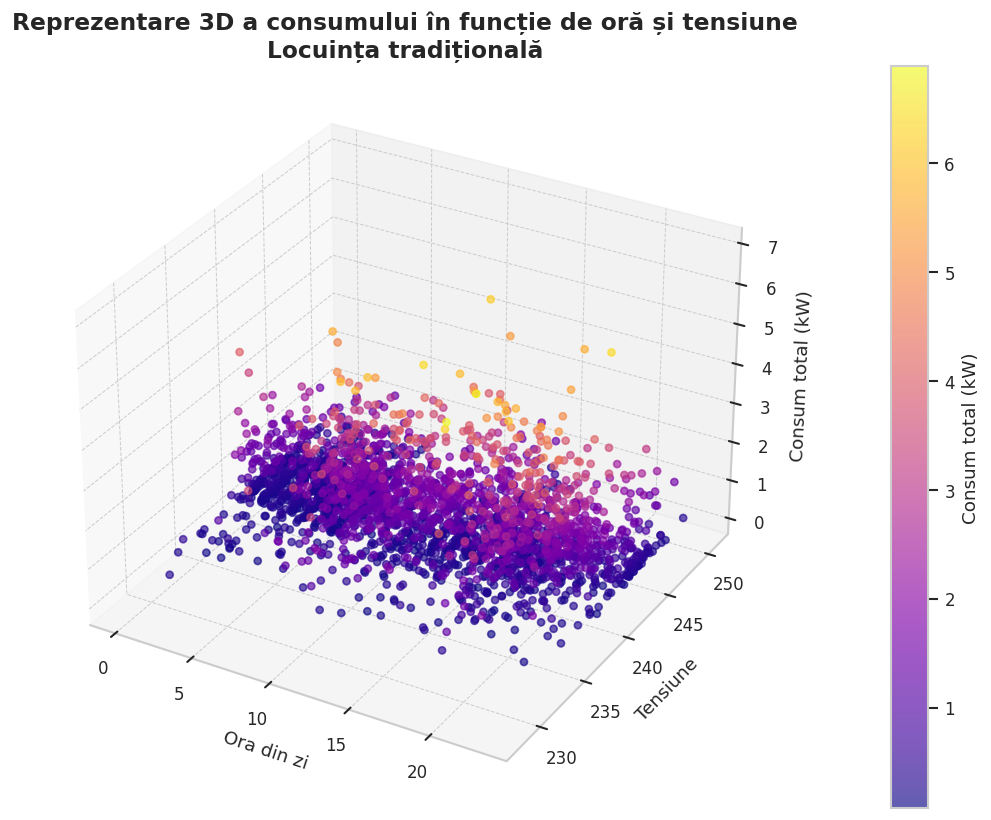

In [ ]:
# =========================
# Grafic 3D - locuința tradițională
# ora, tensiune, consum total
# =========================
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import pandas as pd

analysis_pd["hour"] = pd.to_datetime(analysis_pd["timestamp"]).dt.hour

traditional_3d_df = analysis_pd[["hour", "voltage", "global_active_power"]].dropna().copy()

# eșantion pentru lizibilitate
traditional_3d_sample = traditional_3d_df.sample(
    min(3000, len(traditional_3d_df)),
    random_state=42
)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    traditional_3d_sample["hour"],
    traditional_3d_sample["voltage"],
    traditional_3d_sample["global_active_power"],
    c=traditional_3d_sample["global_active_power"],
    cmap="plasma",
    alpha=0.65,
    s=18
)

ax.set_xlabel("Ora din zi")
ax.set_ylabel("Tensiune")
ax.set_zlabel("Consum total (kW)")
ax.set_title("Reprezentare 3D a consumului în funcție de oră și tensiune\nLocuința tradițională")

cbar = plt.colorbar(scatter, pad=0.1)
cbar.set_label("Consum total (kW)")

plt.tight_layout()
plt.show()

In [ ]:
print("Interval temporal:")
print("Min:", analysis_pd["timestamp"].min())
print("Max:", analysis_pd["timestamp"].max())

Interval temporal:
Min: 2006-12-16 17:24:00
Max: 2010-11-26 21:02:00


In [ ]:
# =========================
# 4. Citirea și inspectarea inițială a setului de date
# =========================
df = spark.read.csv(
    file_name,
    header=True,
    inferSchema=False,   # citim totul ca text
    sep=";",
    nullValue="?",
    mode="DROPMALFORMED"
)

print("Dimensiunea inițială a setului:")
print("Număr rânduri:", df.count())
print("Număr coloane:", len(df.columns))

print("\nSchema inițială a setului:")
df.printSchema()

print("\nPrimele rânduri:")
df.show(5, truncate=False)

# =========================
# 5. Redenumirea și standardizarea coloanelor
# =========================
rename_map = {
    "Global_active_power": "global_active_power",
    "Global_reactive_power": "global_reactive_power",
    "Voltage": "voltage",
    "Global_intensity": "global_intensity",
    "Sub_metering_1": "sub_metering_1",
    "Sub_metering_2": "sub_metering_2",
    "Sub_metering_3": "sub_metering_3"
}

for old_name, new_name in rename_map.items():
    if old_name in df.columns:
        df = df.withColumnRenamed(old_name, new_name)

print("Coloane după redenumire:")
print(df.columns)

# =========================
# 6. Curățarea și conversia variabilei temporale
# =========================
df = df.withColumn("Date", trim(col("Date")))
df = df.withColumn("Time", trim(col("Time")))

# păstrăm doar formatul corect pentru date și oră
df = df.filter(col("Date").rlike(r"^\d{1,2}/\d{1,2}/\d{4}$"))
df = df.filter(col("Time").rlike(r"^\d{2}:\d{2}:\d{2}$"))

# construim direct timestamp-ul corect din Date + Time
df = df.withColumn("timestamp_str", concat_ws(" ", col("Date"), col("Time")))
df = df.withColumn("timestamp", to_timestamp(col("timestamp_str"), "d/M/yyyy HH:mm:ss"))

# eliminăm valorile invalide rămase
df = df.filter(col("timestamp").isNotNull())

print("\nDupă construirea coloanei timestamp:")
print("Număr rânduri:", df.count())
df.select("Date", "Time", "timestamp").show(5, truncate=False)

Dimensiunea inițială a setului:
Număr rânduri: 2075259
Număr coloane: 9

Schema inițială a setului:
root
 |-- Date: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Global_active_power: string (nullable = true)
 |-- Global_reactive_power: string (nullable = true)
 |-- Voltage: string (nullable = true)
 |-- Global_intensity: string (nullable = true)
 |-- Sub_metering_1: string (nullable = true)
 |-- Sub_metering_2: string (nullable = true)
 |-- Sub_metering_3: string (nullable = true)


Primele rânduri:
+----------+--------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|Date      |Time    |Global_active_power|Global_reactive_power|Voltage|Global_intensity|Sub_metering_1|Sub_metering_2|Sub_metering_3|
+----------+--------+-------------------+---------------------+-------+----------------+--------------+--------------+--------------+
|16/12/2006|17:24:00|4.216              |0.418                |234.840|18